<center>

<!-- Ganti dengan logo kampus, misalnya: <img src="URL_LOGO_KAMPUS" width="200"/> -->

<h3>DATERAQUEST 2.0 — Machine Learning Competition</h3>
<h2>Klasifikasi Spesies Tanaman Kebun Raya ITERA:<br>Dari Forensik Korupsi Citra ke Ensemble ResNet yang Robust</h2>

<p><strong>[Nama Fakultas], [Nama Universitas]</strong></p>

</center>

<hr>

### **Anggota Tim ([NAMA TIM])**

- **[Nama Anggota 1]** (<span style="color:gray">[email anggota 1]</span>)
- **[Nama Anggota 2]** (<span style="color:gray">[email anggota 2]</span>)
- **[Nama Anggota 3]** (<span style="color:gray">[email anggota 3]</span>)

<hr>

### **Deskripsi Singkat**

Kompetisi **DATERAQUEST 2.0** meminta peserta mengklasifikasikan citra tanaman ke dalam **30 spesies** koleksi Kebun Raya ITERA. Data latih terdiri atas **3.014 citra berlabel** dan data uji berisi **2.010 citra**, masing-masing dengan tepat satu label kelas. Seluruh model wajib dilatih **dari nol**, tanpa bobot pralatih dari dataset eksternal.

### **Tujuan**

Membangun model klasifikasi yang tetap akurat pada citra uji yang mengalami degradasi berat, dengan validasi lokal yang mencerminkan kondisi tersebut. Penilaian menggunakan **macro F1-score**, sehingga setiap kelas berbobot sama:

$$
F1_{\text{macro}} = \frac{1}{C}\sum_{c=1}^{C} \frac{2\,P_c\,R_c}{P_c + R_c}, \qquad C = 30,
$$

dengan $P_c$ dan $R_c$ adalah presisi dan recall kelas $c$. Peringkat akhir ditentukan oleh **private leaderboard**, sehingga keputusan model didasarkan pada validasi lokal, bukan pada skor publik.

Berkas pengajuan berupa `submission.csv` (2.010 baris, kolom `id,label`) dikumpulkan bersama notebook ini paling lambat **17 November 2026, 23.59 WIB**.

<hr>

### **Narasi Utama**

Notebook ini disusun sebagai rangkaian sebab-akibat dari pemahaman data hingga submission akhir. **Part I** menginvestigasi data dan menemukan bahwa citra uji sengaja dirusak, sedangkan citra latih bersih. **Part II** menerjemahkan temuan tersebut menjadi pembagian fold yang bebas kebocoran dan modul simulasi korupsi untuk augmentasi sekaligus validasi. **Part III** membandingkan strategi augmentasi dan durasi training. **Part IV** mengkalibrasi warna simulasi terhadap statistik citra uji. **Part V** memperluas evaluasi ke lima fold, mengukur selisih validasi terhadap papan peringkat, dan menghasilkan resep final.

**Tesis tim:** citra uji bukan sekadar citra baru, melainkan citra latih yang sengaja dirusak. Kualitas model ditentukan oleh seberapa setia kerusakan itu disimulasikan saat training dan validasi, serta oleh resep training yang tahan terhadapnya, bukan oleh ukuran arsitektur.

<table>
<thead><tr><th>Bagian</th><th>Cakupan</th></tr></thead>
<tbody>
<tr><td><strong>Part I — Investigasi Data</strong></td><td>Setup, integritas label, forensik JPEG, near-duplicate, inspeksi visual, statistik warna dan resolusi (Bagian 1–5)</td></tr>
<tr><td><strong>Part II — Validasi dan Simulasi Korupsi</strong></td><td>Fold bebas kebocoran, modul simulasi korupsi, pipeline data (Bagian 6–8)</td></tr>
<tr><td><strong>Part III — Eksperimen Model Awal</strong></td><td>Fungsi training, perbandingan augmentasi, training panjang, analisis error, submission pertama (Bagian 9–12)</td></tr>
<tr><td><strong>Part IV — Kalibrasi Simulasi Warna</strong></td><td>Iterasi simulasi warna v1–v5 dan model E (Bagian 13–14)</td></tr>
<tr><td><strong>Part V — Validasi 5-Fold dan Resep Final</strong></td><td>OOF lima fold, selisih validasi terhadap papan peringkat, resep F dan H, submission final (Bagian 15–19)</td></tr>
</tbody>
</table>

### **Hasil Ringkas**

<table>
<thead><tr><th>Submission</th><th>Macro F1 validasi v4 (fold 0)</th><th>LB publik</th></tr></thead>
<tbody>
<tr><td>Model E — ResNet-18, 150 epoch, satu model</td><td>0.651</td><td>0.519</td></tr>
<tr><td><strong>Resep F — ResNet-18, 300 epoch, MixUp/CutMix + EMA, ensemble 5 fold</strong></td><td><strong>0.750</strong></td><td><strong>0.677</strong></td></tr>
</tbody>
</table>

Pengantar dan kesimpulan setiap bagian ditulis formal. Observasi setiap eksperimen dicatat dengan gaya catatan kerja (**Q:** → kode → **Observasi:**) agar proses berpikir tetap terlihat.

## Log Temuan

Ringkasan temuan yang membentuk keputusan desain. Kolom *Bukti* merujuk ke nomor bagian di notebook ini.

| # | Temuan | Bukti | Implikasi |
|---|---|---|---|
| F1 | CSV bersih: no missing/dup, label = prefix folder, file disk = CSV | Bagian 2 | Gak perlu cleaning tabular |
| F2 | 30 kelas, imbalance moderat 47–169 (3.6×) | Bagian 2 | Pantau F1 per kelas |
| F3 | Test **JPEG q 10–50** (~70% di 10–25), train q=91 konstan, file 8× lebih kecil | Bagian 3 | `ImageCompression(10–50)` di train aug + validasi |
| F4 | Test **dikorupsi sintetis**: hue/tint, gray ~11%, border hitam ~38%, poligon/shadow, cutout, fog/flare/rain | Bagian 4–5 | Augmentasi korupsi; **validasi lokal juga dikorupsi** |
| F5 | Hue test sebarannya 2× lebih lebar dari train | Bagian 5 | Hue shift agresif |
| F6 | Near-duplicate di train (pHash ≤8, 7 group) | Bagian 4, 6 | StratifiedGroupKFold |
| F7 | Resolusi ↔ kelas berkorelasi (artefak device) | Bagian 5 | Gak dipakai sebagai fitur |
| F8 | Resolusi/komposisi train = test, EXIF kosong | Bagian 3 | Test dari sumber sama + degradasi |
| F9 | Simulasi v1 cocok di border/gray/hue/sat, tapi **chroma terlalu rendah** (~28 vs 48) | Bagian 7 | Tuning warna (→ F15) |
| F10 | `RandomFog` ~600 ms/gambar; worker import torch sendiri → RAM swap | Bagian 8 | Ganti `haze`, forkserver preload `dq`, 10 worker |
| F11 | Aug clean: val bersih 0.78 tapi **val corrupt 0.34** | Bagian 10 | Val bersih gak bisa dipercaya |
| F12 | `mix` 50/50 > full corrupt (0.450 vs 0.403 @60ep); 150 ep → **0.627** (+TTA) | Bagian 10–11 | Pakai `mix`, training lama |
| F13 | Kelas penyedot (Dendrobium leonis +17, Ochna +12); logit adjustment gak bantu | Bagian 11 | Perbaiki representasi, bukan prior |
| F14 | Prediksi test over-predict Cuphea & Lxora (bunga warna nyolok), korelasi distribusi 0.51 | Bagian 12 | Konsisten sama F9, benerin simulasi warna |
| F15 | Tint test **diagonal** (channel G geser sendiri, ijo↔magenta), sat lebih tinggi; geometric diterapin **setelah** warna | Bagian 13 | Pipeline `corrupt_v4`: RGBShift G ±80, sat boost, Affine setelah warna |
| F16 | Val v1 terlalu optimis: model D 0.627 di v1 tapi 0.578 di val v4 | Bagian 14 | Pakai **val v4** buat keputusan |
| F17 | Model E (aug v4) **0.651** di val v4 (D 0.578); over-predict Cuphea/Lxora di test berkurang; ensemble D+E malah turun (0.634) | Bagian 14 | Submission dari E; Dendrobium leonis masih penyedot |
| F18 | 5-fold resep E: OOF F1 val v4 **0.630** (fold 0.614–0.651); tiap fold setuju ~68% sama ensemble di test | Bagian 15 | Submission = rata-rata 5 fold; estimasi realistis ~0.63 |
| F19 | LB model E **0.519** vs val v4 0.651: test lebih susah dari simulasi; median keyakinan model di test 0.34 vs 0.51 di val | Bagian 16 | Val v4 masih optimis; LB dipakai buat konfirmasi |
| F20 | Resep F (300 ep + MixUp/CutMix + EMA): val v4 fold 0 **0.750** (E 0.651), konsisten naik di 5 fold; LB **0.677** | Bagian 17–19 | Submission final = ensemble 5-fold F |
| F21 | Korupsi lebih berat (H: blur/noise/downscale, JPEG 5–40) malah turun (0.626 vs 0.651) | Bagian 17 | Gap ke test bukan karena korupsi kurang parah |

# Part I — Investigasi Data

Bagian pertama memetakan karakter data sebelum model dibangun. Fokusnya adalah memastikan label bersih, mengukur seberapa jauh citra uji berbeda dari citra latih, dan menemukan pola yang dapat membuat validasi lokal terlalu optimistis. Setiap temuan dicatat pada Log Temuan beserta bagian yang menjadi buktinya.

## 1. Setup

Pustaka, opsi tampilan, dan seed global. Sel kedua menetapkan gaya visual yang seragam untuk seluruh plot (palet ramah buta warna).

In [1]:
import os, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", 50)
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA = Path("dateraquest-2-0-machine-learning-competition")
sorted(p.name for p in DATA.iterdir())

['class_mapping.csv', 'sample_submission.csv', 'test', 'train', 'train.csv']

In [2]:
# Gaya visual seragam untuk semua plot (palet ramah buta warna; perbedaan gak cuma lewat warna)
import matplotlib as mpl
COL = dict(train="#2a78d6", test="#eb6834", ok="#1baf7a", bad="#e34948", warn="#eda100", violet="#4a3aa7",
           ink="#0b0b0b", ink2="#52514e", muted="#8a8984", grid="#e6e5e1", surface="#fcfcfb")
mpl.rcParams.update({
    "figure.facecolor": COL["surface"], "axes.facecolor": COL["surface"], "savefig.facecolor": COL["surface"],
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": COL["ink2"], "xtick.color": COL["ink2"], "ytick.color": COL["ink2"],
    "axes.edgecolor": COL["muted"], "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COL["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 100,
    "axes.prop_cycle": mpl.cycler(color=[COL[k] for k in ("train", "test", "ok", "violet", "warn", "bad")]),
})

## 2. Inventaris data dan integritas label

Pemeriksaan struktur `train.csv`, `sample_submission.csv`, dan `class_mapping.csv`: kolom, tipe, nilai hilang, duplikat, kecocokan label dengan folder, serta distribusi kelas.

**Q:** Bentuk `train.csv`, `test` (via sample_submission), sama `class_mapping` kayak gimana? Kolomnya apa aja, tipenya bener gak?

In [3]:
train = pd.read_csv(DATA / "train.csv")
sub = pd.read_csv(DATA / "sample_submission.csv")
cmap = pd.read_csv(DATA / "class_mapping.csv")
for name, df in [("train", train), ("sample_sub", sub), ("class_map", cmap)]:
    print(f"== {name}: {df.shape}")
    df.info()
    print()

== train: (3014, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3014 entries, 0 to 3013
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      3014 non-null   object
 1   label   3014 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 47.2+ KB

== sample_sub: (2010, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2010 entries, 0 to 2009
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2010 non-null   object
 1   label   2010 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 31.5+ KB

== class_map: (30, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   label        30 non-null     int64 
 1   species      30 non-null     object
 2   folder_name  30 non-null     object
dtypes: int64(1), obje

In [4]:
display(train.sample(5, random_state=SEED))
display(sub.head(3)); display(sub.tail(3))
cmap.head()

,id,label
291,3_Apocynacaea/3_82.jpg,3
2576,26_Rosa_sp/26_8.jpg,26
1547,15_Impatiens_walleriana/15_50.jpg,15
2737,27_Russelia_equisetiformis/27_72.jpg,27
1102,11_Dracaena_Trifasciata_Mabb/11_51.jpg,11


,id,label
0,test_0001.jpg,0
1,test_0002.jpg,0
2,test_0003.jpg,0


,id,label
2007,test_2008.jpg,0
2008,test_2009.jpg,0
2009,test_2010.jpg,0


,label,species,folder_name
0,0,Albizia_saponaria,0_Albizia_saponaria
1,1,Alocasia_Black_Velvet,1_Alocasia_Black_Velvet
2,2,Anacampseros_rufescens_Sunrise,2_Anacampseros_rufescens_Sunrise
3,3,Apocynacaea,3_Apocynacaea
4,4,Areca_catechu_L,4_Areca_catechu_L


**Observasi:** Struktur simpel banget. `train` 3014 baris × 2 kolom (`id` = path relatif `folder/file.jpg`, `label` int). Sample sub 2010 baris, id `test_0001.jpg`..`test_2010.jpg`, label default 0. `class_mapping` 30 kelas, `folder_name` = `{label}_{species}`. Gak ada fitur tabular, jadi "data" aslinya ya gambarnya.

**Q:** Sebelum lanjut, cek integritas dulu: ada missing / duplikat? `label` di CSV konsisten gak sama prefix folder-nya? Semua file di CSV beneran ada di disk, dan sebaliknya?

In [5]:
print("missing train:", train.isna().sum().to_dict(), "| missing sub:", sub.isna().sum().to_dict())
print("duplicate id train:", train.id.duplicated().sum(), "| duplicate id sub:", sub.id.duplicated().sum())

train["folder"] = train.id.str.split("/").str[0]
folder2label = dict(zip(cmap.folder_name, cmap.label))
print("label != label dari folder:", (train.folder.map(folder2label) != train.label).sum())

disk_train = {str(p.relative_to(DATA / "train")) for p in (DATA / "train").rglob("*") if p.is_file()}
disk_test = {p.name for p in (DATA / "test").iterdir() if p.is_file()}
print("train: di CSV tapi gak di disk:", len(set(train.id) - disk_train), "| di disk tapi gak di CSV:", len(disk_train - set(train.id)))
print("test : di sub tapi gak di disk:", len(set(sub.id) - disk_test), "| di disk tapi gak di sub:", len(disk_test - set(sub.id)))
print("ekstensi file:", pd.Series([Path(p).suffix.lower() for p in disk_train | disk_test]).value_counts().to_dict())

missing train: {'id': 0, 'label': 0} | missing sub: {'id': 0, 'label': 0}
duplicate id train: 0 | duplicate id sub: 0
label != label dari folder: 0
train: di CSV tapi gak di disk: 0 | di disk tapi gak di CSV: 0
test : di sub tapi gak di disk: 0 | di disk tapi gak di sub: 0
ekstensi file: {'.jpg': 5024}


**Observasi:** Bersih. Gak ada missing, gak ada id duplikat, label di CSV 100% cocok sama prefix folder, dan file di disk = file di CSV (train 3014, test 2010, semuanya `.jpg`). Jadi gak perlu cleaning di level CSV.

**Q:** Distribusi target gimana? Macro F1 ngasih bobot sama ke tiap kelas, jadi penting tau seberapa imbalanced.

{'count': 30.0, 'mean': 100.5, 'std': 31.5, 'min': 47.0, '25%': 76.8, '50%': 101.0, '75%': 120.8, 'max': 169.0}
rasio max/min: 3.60


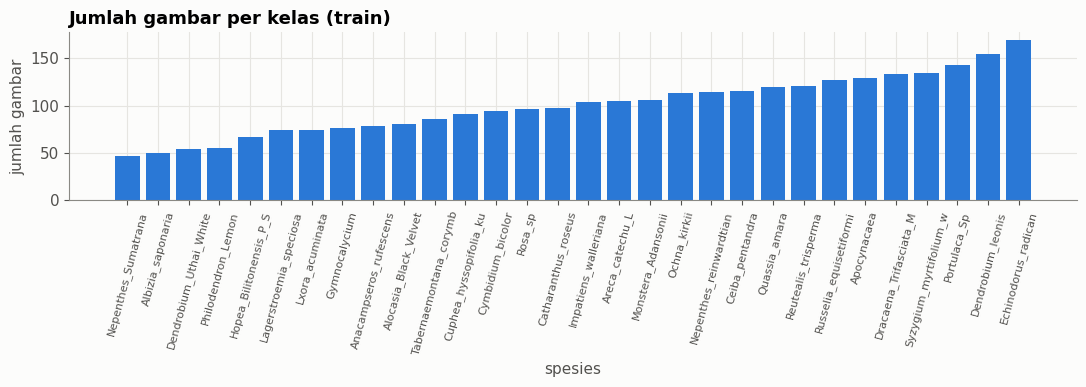

In [6]:
vc = train.label.value_counts().sort_values()
print(vc.describe().round(1).to_dict())
print(f"rasio max/min: {vc.max()/vc.min():.2f}")
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar([cmap.species[i][:22] for i in vc.index], vc.values)
ax.set_title("Jumlah gambar per kelas (train)"); ax.set_xlabel("spesies"); ax.set_ylabel("jumlah gambar")
plt.xticks(rotation=75, fontsize=8); plt.tight_layout(); plt.show()

**Observasi:** Imbalance-nya moderat. Rata-rata ~100 gambar/kelas, paling dikit *Nepenthes Sumatrana* (47) sama *Albizia saponaria* (50), paling banyak *Echinodorus radican* (169). Rasio max/min 3.6×. Gak ekstrem, tapi ada sekitar 5 kelas di bawah 70 gambar, dan buat macro F1 itu bakal jadi titik lemah. Distribusinya lumayan rata naik, gak ada satu kelas yang dominan banget.

**Q:** Nama file pola-nya `{label}_{nomor}.jpg`. Nomornya urut nyambung gak per kelas? Kalau bolong-bolong, bisa jadi sebagian dari urutan yang sama dipindah ke test (artinya test mungkin dari sesi foto yang sama).

In [7]:
train["num"] = train.id.str.extract(r"_(\d+)\.jpg$")[0].astype(int)
g = train.groupby("label").num.agg(n="count", mn="min", mx="max")
g["bolong"] = g.mx - g.mn + 1 - g.n
print("total bolong:", g.bolong.sum(), "| kelas yg ada bolongnya:", (g.bolong > 0).sum())
g.sort_values("bolong", ascending=False).head(8)

total bolong: 0 | kelas yg ada bolongnya: 0


,n,mn,mx,bolong
label,,,,
0,50,1,50,0
1,81,1,81,0
2,79,1,79,0
3,129,1,129,0
4,105,1,105,0
5,98,1,98,0
6,116,1,116,0
7,91,1,91,0


**Observasi:** Nomor file per kelas urut rapi dari 1 sampai n, gak ada yang bolong sama sekali. Berarti file-nya di-rename **setelah** split (atau test-nya emang koleksi terpisah). Dari nama file gak bisa nyimpulin apa-apa soal hubungan train-test. Inconclusive, lanjut aja.

## Deep dives: properti gambar

**Q:** Gambarnya sendiri kayak gimana? Resolusi, aspect ratio, color mode, ukuran file, sama kualitas JPEG (ditebak dari quantization table). Train vs test beda gak? Ini penting karena deskripsi lomba bilang test bisa dari "waktu/lokasi/perangkat berbeda".

## 3. Forensik citra uji: format dan kompresi JPEG

Perbandingan metadata berkas citra latih dan uji (mode warna, resolusi, ukuran berkas, EXIF) serta estimasi kualitas JPEG dari tabel kuantisasi. Bagian ini menguji apakah citra uji berasal dari distribusi yang sama dengan citra latih.

In [8]:
from concurrent.futures import ThreadPoolExecutor

STD_LUMA_DC = 16  # nilai DC tabel kuantisasi luma standar JPEG (quality 50)

def jpeg_quality(q0):
    # tebak quality IJG dari skala tabel: scale = q0/16*100; q<50 -> 5000/scale, q>=50 -> (200-scale)/2
    s = q0 / STD_LUMA_DC * 100
    return round(5000 / s) if s > 100 else round((200 - s) / 2)

def img_meta(path):
    im = Image.open(path)
    q = im.quantization[0][0] if getattr(im, "quantization", None) else np.nan
    w, h = im.size
    im.draft("RGB", (w // 8, h // 8))  # decode kecil biar cepet, cukup buat statistik warna
    a = np.asarray(im.convert("RGB"), dtype=np.float32)
    return dict(w=w, h=h, mode=im.mode, kb=os.path.getsize(path) / 1024, q_dc=q,
                quality=jpeg_quality(q), bright=a.mean(), contrast=a.std(),
                r=a[..., 0].mean(), g=a[..., 1].mean(), b=a[..., 2].mean(),
                exif_n=len(im.getexif()))

paths = [DATA / "train" / i for i in train.id] + [DATA / "test" / i for i in sub.id]
with ThreadPoolExecutor(16) as ex:
    meta = pd.DataFrame(list(ex.map(img_meta, paths)))
meta["split"] = ["train"] * len(train) + ["test"] * len(sub)
meta["id"] = list(train.id) + list(sub.id)
meta["aspect"] = (meta.w / meta.h).round(3)
meta["mpix"] = meta.w * meta.h / 1e6
meta.groupby("split")[["w", "h", "aspect", "mpix", "kb", "quality", "bright", "contrast", "exif_n"]].median().T

split,test,train
w,608.000000,608.000000
h,1024.000000,1024.000000
aspect,0.563000,0.563000
mpix,0.656640,0.656640
kb,29.178223,226.549805
quality,21.000000,91.000000
bright,95.404694,105.706009
contrast,53.477249,51.364891
exif_n,0.000000,0.000000


**Observasi:** Ini temuan paling gede sejauh ini 🚨
- Resolusi/aspect median **sama persis** (608×1024, portrait, ~0.66 MP). Jadi bukan beda di ukuran.
- **Ukuran file test ~8× lebih kecil** (29 KB vs 227 KB), dan estimasi **JPEG quality test ~21 vs train ~91**. Test dikompres jauh lebih brutal.
- Test juga sedikit **lebih gelap** (median brightness 95 vs 106), kontras mirip.
- EXIF kosong di dua-duanya, jadi gak bisa ngecek device/waktu dari metadata.

**Q:** Gap kualitas ini konsisten di semua gambar, atau cuma sebagian test yang dikompres? Terus resolusi/mode-nya variasinya kayak apa?

color mode: {('test', 'RGB'): 2010, ('train', 'RGB'): 3014}

quality per split (describe):


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,2010.0,25.1,12.4,10.0,15.0,21.0,36.0,50.0
train,3014.0,91.0,0.0,91.0,91.0,91.0,91.0,91.0


top 5 resolusi per split:
train {(608, 1080): 1442, (768, 1024): 507, (1080, 608): 230, (1024, 768): 187, (1024, 683): 104}
test {(608, 1080): 963, (768, 1024): 335, (1080, 608): 153, (1024, 768): 114, (1024, 683): 90}


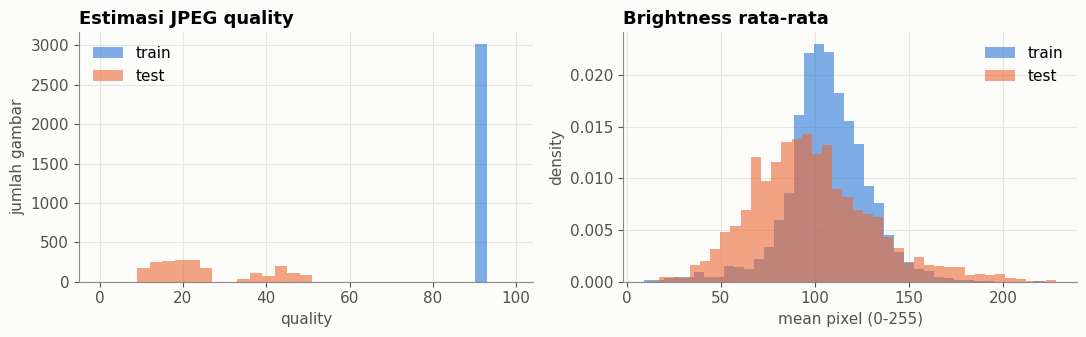

In [9]:
print("color mode:", meta.groupby("split")["mode"].value_counts().to_dict())
print("\nquality per split (describe):")
display(meta.groupby("split").quality.describe().round(1))
print("top 5 resolusi per split:")
for s in ["train", "test"]:
    print(s, meta[meta.split == s].groupby(["w", "h"]).size().sort_values(ascending=False).head(5).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for s in ["train", "test"]:
    axes[0].hist(meta[meta.split == s].quality, bins=range(0, 102, 3), alpha=.6, label=s)
    axes[1].hist(meta[meta.split == s].bright, bins=40, alpha=.6, label=s, density=True)
axes[0].set(title="Estimasi JPEG quality", xlabel="quality", ylabel="jumlah gambar")
axes[1].set(title="Brightness rata-rata", xlabel="mean pixel (0-255)", ylabel="density")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

**Observasi:**
- Semua RGB. Distribusi resolusi train vs test **proporsinya hampir sama persis** (608×1080 ≈ 48% di dua-duanya, 768×1024 ≈ 17%, dst).
- **Train quality = 91 semua, konstan.** Test kesebar **10–50**, ada dua gerombol (≈10–27 sama ≈35–50). Gak ada satupun gambar test di atas 50.
- Brightness test bukan cuma geser lebih gelap, tapi juga **lebih lebar sebarannya** (ada ekor gelap ~40-60 DAN ekor terang ~170-210 yang di train jarang).

Hipotesis: test kayaknya diambil dari "sumber" yang sama kayak train (komposisi resolusi identik), terus **sengaja didegradasi secara sintetis**, yaitu kompresi JPEG random q∈[10,50] + random brightness (mungkin juga yang lain). Kalau bener, ini kabar baik: shift-nya bisa disimulasiin pakai augmentation.

**Q:** Quality test persisnya nilai apa aja? Kalau itu uniform random, harusnya kesebar rata di 10–50.

In [10]:
qt = meta[meta.split == "test"].quality.value_counts().sort_index()
print(qt.to_dict())

{10: 90, 11: 87, 12: 81, 13: 92, 14: 71, 15: 92, 16: 89, 17: 87, 18: 84, 19: 83, 20: 106, 21: 84, 22: 91, 23: 102, 24: 82, 25: 86, 35: 29, 36: 79, 38: 32, 40: 70, 42: 119, 44: 86, 47: 107, 50: 81}


**Observasi:** q=10..25 masing-masing ~80-100 gambar (kayak uniform), terus q=35..50 lebih jarang dan nilainya lompat-lompat. Lompatannya wajar, karena estimasi dari DC table makin kasar di quality tinggi. Yang menarik, **q 26–34 kosong total**. Kesimpulan kasar: ~70% test di q≈10–25, ~30% di q≈35–50. Augmentasi JPEG di training harus nyakup range **10–50**, dengan porsi besar di quality rendah.

**Q:** Ada gambar yang (hampir) duplikat gak? (a) Train-train: kalau ada foto kembar/burst, harus satu fold biar CV gak bocor. (b) Train-test: kalau test isinya versi rusak dari foto train, itu ngaruh banget ke strategi. Pakai perceptual hash (pHash), yang tahan sama kompresi + brightness.

## 4. Near-duplicate dan inspeksi visual

Perceptual hash (pHash) dipakai untuk mendeteksi pasangan citra yang hampir identik dan berpotensi bocor antar-fold. Galeri citra kemudian memperlihatkan bentuk degradasi pada citra uji secara langsung.

In [11]:
import imagehash

def phash(path):
    im = Image.open(path); im.draft("RGB", (im.size[0] // 4, im.size[1] // 4))
    return imagehash.phash(im.convert("RGB"), hash_size=8)

with ThreadPoolExecutor(16) as ex:
    hashes = list(ex.map(phash, paths))
H = np.array([h.hash.flatten() for h in hashes], dtype=np.uint8)  # (N, 64) bit
ntr = len(train)
# hamming distance semua pasangan, pakai trik matmul biar cepet
Hf = H.astype(np.float32)
D = Hf @ (1 - Hf).T + (1 - Hf) @ Hf.T
np.fill_diagonal(D, 99)
d_tr_tr = D[:ntr, :ntr]; d_te_tr = D[ntr:, :ntr]
print("train-train  min dist per gambar:", pd.Series(d_tr_tr.min(1)).describe().round(1).to_dict())
print("test-train   min dist per gambar:", pd.Series(d_te_tr.min(1)).describe().round(1).to_dict())
for t in [0, 4, 8, 12]:
    print(f"dist<={t:2d}: train punya kembaran di train = {(d_tr_tr.min(1) <= t).sum():4d} | test punya kembaran di train = {(d_te_tr.min(1) <= t).sum():4d}")

train-train  min dist per gambar: {'count': 3014.0, 'mean': 17.3, 'std': 1.6, 'min': 8.0, '25%': 16.0, '50%': 18.0, '75%': 18.0, 'max': 20.0}
test-train   min dist per gambar: {'count': 2010.0, 'mean': 17.5, 'std': 1.4, 'min': 10.0, '25%': 16.0, '50%': 18.0, '75%': 18.0, 'max': 20.0}
dist<= 0: train punya kembaran di train =    0 | test punya kembaran di train =    0
dist<= 4: train punya kembaran di train =    0 | test punya kembaran di train =    0
dist<= 8: train punya kembaran di train =   14 | test punya kembaran di train =    0
dist<=12: train punya kembaran di train =   53 | test punya kembaran di train =    5


**Observasi:** Gak ada duplikat persis (dist 0–4 = nol). Jarak minimum tipikal ~17–18 bit. Itu angka yang memang wajar buat gambar yang gak berhubungan (min dari ~3000 sampel binomial(64, 0.5) ya kira-kira segitu). Ada sedikit pasangan dekat: 14 gambar train dengan dist ≤8, dan 5 gambar test dengan dist ≤12 ke train.

**Q:** Pasangan terdekat itu beneran foto tanaman yang sama (burst/beda angle dikit), atau cuma kebetulan mirip komposisinya?

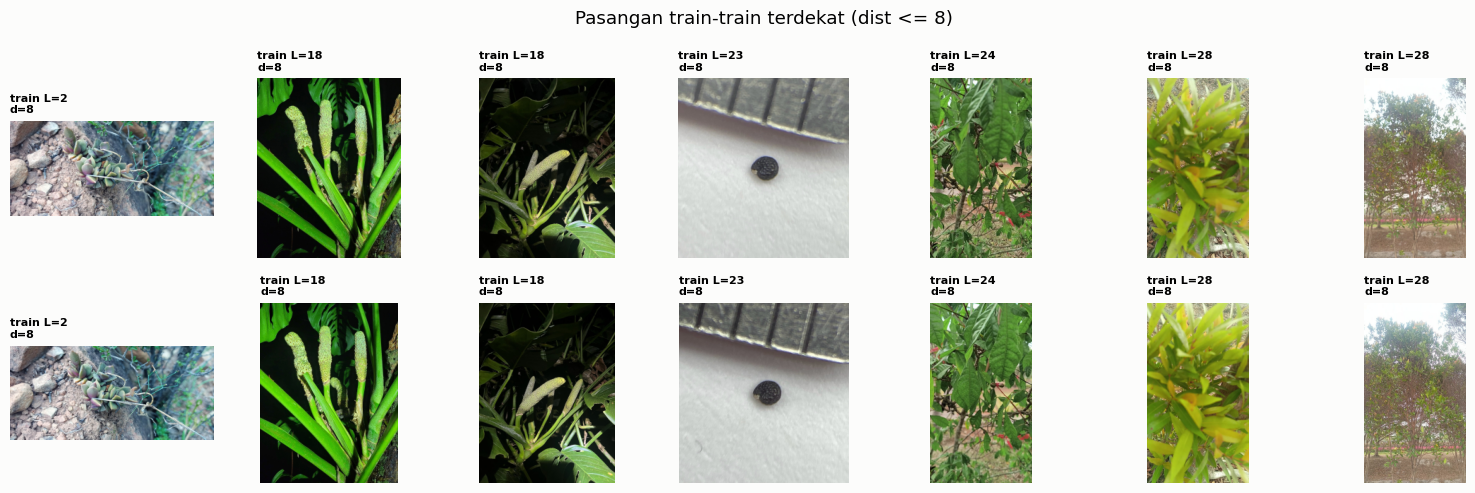

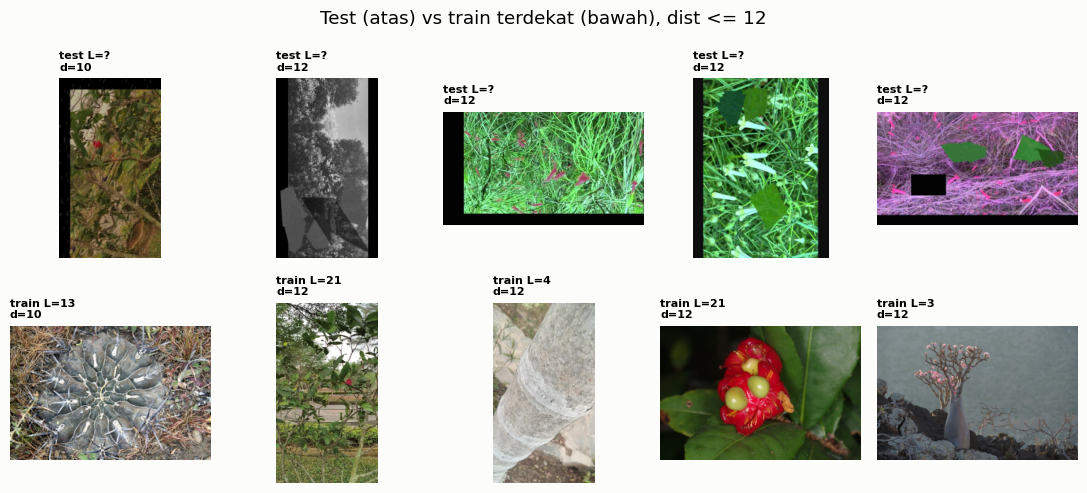

In [12]:
def show_pairs(pairs, title):
    fig, axes = plt.subplots(2, len(pairs), figsize=(2.2 * len(pairs), 5))
    for j, (a, b, d) in enumerate(pairs):
        for i, k in enumerate([a, b]):
            axes[i, j].imshow(Image.open(paths[k]).reduce(4)); axes[i, j].axis("off")
            axes[i, j].set_title(f"{meta.split[k]} L={train.label[k] if k < ntr else '?'}\nd={int(d)}", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

iu = np.argwhere(np.triu(d_tr_tr <= 8))
tt = [(a, b, d_tr_tr[a, b]) for a, b in iu][:7]
show_pairs(tt, "Pasangan train-train terdekat (dist <= 8)")
te = np.where(d_te_tr.min(1) <= 12)[0]
show_pairs([(ntr + i, d_te_tr[i].argmin(), d_te_tr[i].min()) for i in te], "Test (atas) vs train terdekat (bawah), dist <= 12")

**Observasi:** Dua hal penting nih:
1. **Train-train dist ≤8 memang near-duplicate beneran.** Ada yang identik secara visual (L=2, L=18, L=23, L=24), ada juga yang kayak burst beda framing dikit (L=28). Jumlahnya kecil (~14 gambar), tapi tetep: kelompokin di fold yang sama biar gak bocor.
2. **Pasangan test-train itu false positive. Test-nya sendiri yang aneh banget!** Gambar test-nya kelihatan **dirusak sengaja**: ada border hitam (gambar digeser/di-rotate terus di-pad hitam), ada yang **grayscale**, ada yang **warnanya kebalik/hue geser** (rumput jadi pink-ungu), ada **kotak hitam** (cutout), dan ada **tempelan bentuk hijau** kayak potongan daun/poligon yang nutupin objek. pHash-nya mirip karena border hitam itu, bukan karena kontennya sama.

Hipotesis diperbarui: test = gambar "normal" + **pipeline korupsi sintetis yang berat** (geometric shift/rotate + color corruption + occlusion + JPEG jelek). Ini jauh lebih ekstrim dari sekadar "difoto beda device".

**Q:** Seberapa umum korupsi ini di test? Bandingin sampel random 12 test vs 12 train (tanpa pilih-pilih).

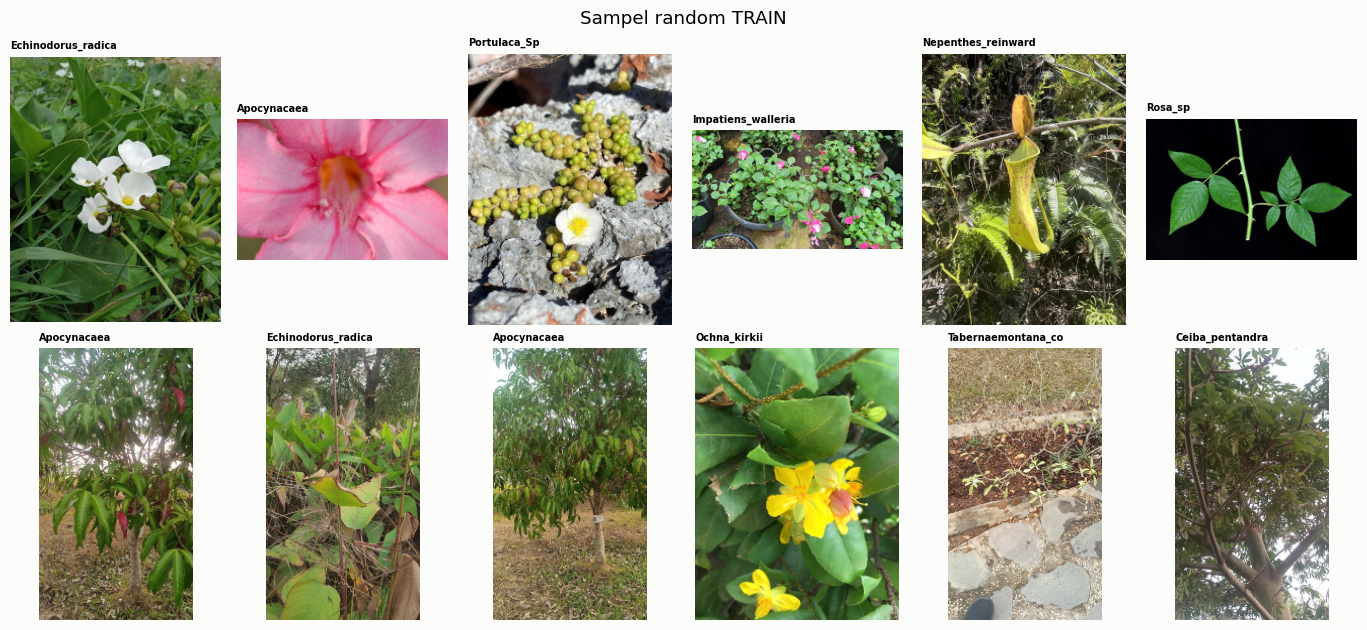

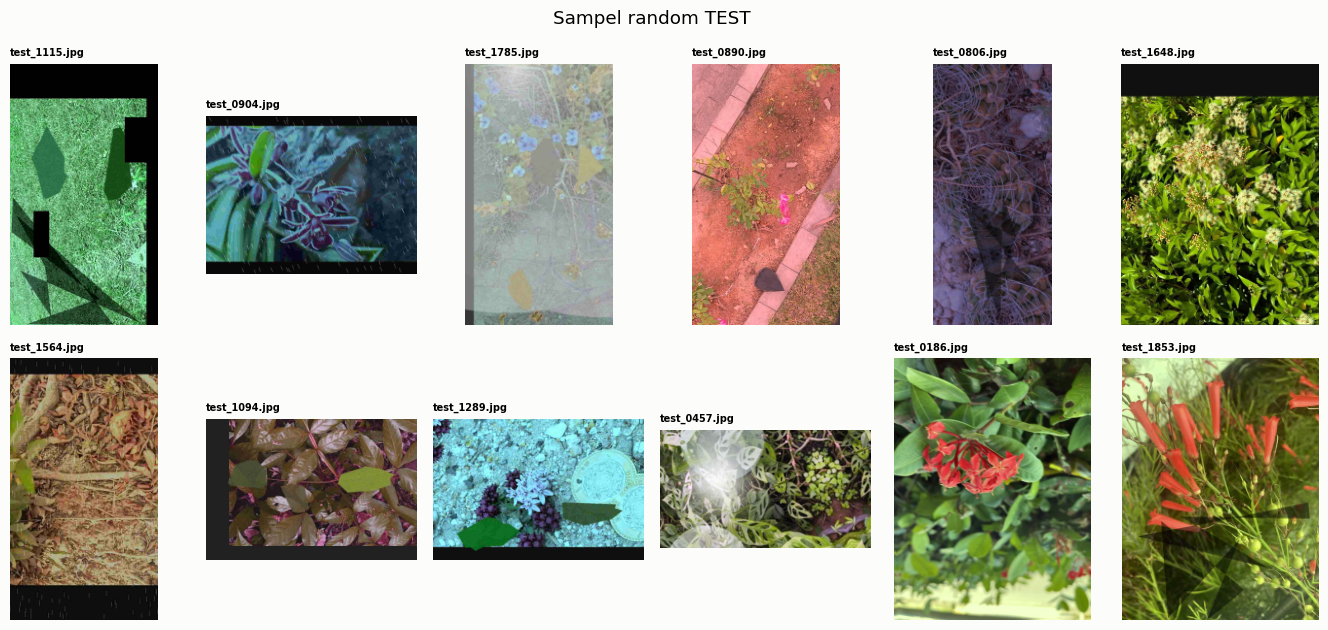

In [13]:
def grid(idx, title, ncol=6):
    nrow = int(np.ceil(len(idx) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.3 * ncol, 3.2 * nrow))
    for ax, k in zip(axes.flat, idx):
        ax.imshow(Image.open(paths[k]).reduce(4)); ax.axis("off")
        lab = cmap.species[train.label[k]][:18] if k < ntr else Path(paths[k]).name
        ax.set_title(lab, fontsize=7)
    for ax in axes.flat[len(idx):]: ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
grid(rng.choice(ntr, 12, replace=False), "Sampel random TRAIN")
grid(ntr + rng.choice(len(sub), 12, replace=False), "Sampel random TEST")

**Observasi:** Kontrasnya parah banget 😅
- **Train:** foto HP biasa, bersih, warna natural. Objeknya macem-macem: close-up bunga, satu pohon utuh, semak, bahkan foto dengan background hitam (Rosa sp). Variasi skala gede banget.
- **Test:** hampir **semua** sampel kena korupsi, sering lebih dari satu sekaligus:
  - **Pergeseran warna/hue/tint** (hijau, cyan, ungu, salmon), kadang grayscale-ish
  - **Border hitam/abu** di sisi gambar (translate/shift dengan fill konstan), kadang ada **garis-garis kayak hujan** (test_1564, test_0904)
  - **Poligon semi-transparan** (hijau/abu/kuning/gelap), mirip `RandomShadow` + occluder warna
  - **Kotak hitam** (CoarseDropout)
  - **Kabut/washed out** (test_1785), **sun flare** lingkaran putih (test_0457)
  - Rotasi/tilt dikit (test_1853)
  - Plus JPEG jelek tadi.

  Ini kelihatan kayak pipeline augmentasi ala **albumentations** (`RandomShadow`, `RandomSunFlare`, `RandomFog`, `RandomRain`, `CoarseDropout`, `HueSaturationValue`/`RGBShift`, `Affine` dengan border konstan, `ImageCompression`) yang dipasang ke test.

Implikasi gede: **model yang cuma dilatih di gambar bersih bakal jeblok di test.** Training augmentation harus meniru korupsi-korupsi ini, dan validasi lokal juga harus dikorupsi dengan cara yang sama biar skornya mirip test.

**Q:** Coba kuantifikasi kasar beberapa korupsi yang gampang dideteksi: proporsi gambar dengan border gelap, grayscale, dan statistik saturasi + hue di train vs test.

## 5. Statistik warna dan resolusi

Pengukuran sebaran hue, saturasi, dan chroma pada citra latih dan uji, serta hubungan resolusi citra dengan kelas sebagai indikasi artefak perangkat.

In [14]:
import colorsys

def corrupt_stats(path):
    im = Image.open(path); im.draft("RGB", (im.size[0] // 4, im.size[1] // 4))
    a = np.asarray(im.convert("RGB"), dtype=np.float32)
    lum = a.mean(2); k = max(2, int(0.03 * min(lum.shape)))  # strip 3% di tiap sisi
    edges = [lum[:k], lum[-k:], lum[:, :k], lum[:, -k:]]
    dark_side = sum(e.mean() < 25 for e in edges)  # sisi yang hampir hitam
    chroma = (a.max(2) - a.min(2)).mean()          # ~0 kalau grayscale
    hsv = np.asarray(im.convert("RGB").convert("HSV"), dtype=np.float32)
    return dict(dark_sides=dark_side, chroma=chroma, sat=hsv[..., 1].mean(), hue=hsv[..., 0].mean())

with ThreadPoolExecutor(16) as ex:
    cs = pd.DataFrame(list(ex.map(corrupt_stats, paths)))
cs["split"] = meta.split
print("% gambar dengan >=1 sisi hitam:", (cs.dark_sides >= 1).groupby(cs.split).mean().round(3).to_dict())
print("% gambar grayscale (chroma < 6):", (cs.chroma < 6).groupby(cs.split).mean().round(3).to_dict())
display(cs.groupby("split")[["chroma", "sat", "hue"]].describe().T.round(1))

% gambar dengan >=1 sisi hitam: {'test': 0.382, 'train': 0.03}
% gambar grayscale (chroma < 6): {'test': 0.106, 'train': 0.001}


split           test   train
chroma count  2010.0  3014.0
       mean     49.7    45.7
       std      30.3    20.5
       min       0.0     1.7
       25%      29.9    30.9
       50%      48.0    42.4
       75%      68.5    57.7
       max     213.3   184.2
sat    count  2010.0  3014.0
       mean     97.1    97.5
       std      52.0    38.3
       min       0.0     9.6
       25%      66.4    68.5
       50%     100.4    94.1
       75%     133.1   120.7
       max     244.4   233.0
hue    count  2010.0  3014.0
       mean     78.2    61.2
       std      52.6    24.6
       min       0.0     7.0
       25%      40.8    45.3
       50%      68.6    55.6
       75%     110.6    72.0
       max     234.5   222.2

**Observasi:**
- **38% test punya minimal satu sisi hitam** (train cuma 3%, dan itu wajar, foto malam/background gelap). Jadi shift/rotate + border fill itu korupsi yang sering.
- **~10.6% test grayscale** vs 0.1% train. Kira-kira `ToGray(p≈0.1)`.
- **Hue di test kesebar 2× lebih lebar** (std 52.6 vs 24.6), median geser dari 56 ke 69. Artinya ada hue shift yang gede, bukan cuma tweak kecil. Saturasi juga lebih lebar (ada yang jadi 0, ada yang naik).

Implikasi buat augmentation: hue shift harus cukup agresif (bertentangan sama insting awal "jangan geser hue biar warna bunga tetap"). Model harus belajar ngandelin **bentuk/tekstur**, bukan cuma warna.

**Q:** Satu hal lagi: resolusi asli dipertahankan di test (komposisinya sama kayak train). Resolusi/orientasi berkorelasi sama kelas gak? Kalau iya, itu "fitur gratis" yang hilang kalau kita resize semua ke kotak, dan bisa dipakai sebagai input tambahan.

In [15]:
meta["res"] = meta.w.astype(str) + "x" + meta.h.astype(str)
mt = meta[meta.split == "train"].assign(label=train.label.values)
print("jumlah resolusi unik train/test:", mt.res.nunique(), meta[meta.split == "test"].res.nunique())
ct = pd.crosstab(mt.label, mt.res)
top = ct.sum().sort_values(ascending=False).index[:6]
purity = (ct.max(1) / ct.sum(1)).rename("res_dominan_%")
display(pd.concat([ct[top], purity.round(2)], axis=1).rename(index=lambda i: cmap.species[i][:20]).sort_values("res_dominan_%", ascending=False).head(12))
# seberapa banyak info: akurasi kalau tebak kelas mayoritas per resolusi (in-sample, upper bound kasar)
maj = mt.groupby("res").label.agg(lambda s: s.value_counts().index[0])
print("akurasi 'tebak dari resolusi doang' (in-sample):", (mt.res.map(maj) == mt.label).mean().round(3), "| baseline mayoritas:", round(mt.label.value_counts().iloc[0] / len(mt), 3))

jumlah resolusi unik train/test: 186 136


,608x1080,768x1024,1080x608,1024x768,1024x683,576x1024,res_dominan_%
label,,,,,,,
Dendrobium_Uthai_Whi,0,0,54,0,0,0,1.00
Philodendron_Lemon,55,0,0,0,0,0,1.00
Alocasia_Black_Velve,79,2,0,0,0,0,0.98
Albizia_saponaria,49,1,0,0,0,0,0.98
Tabernaemontana_cory,82,1,0,1,0,0,0.95
Hopea_Bilitonensis_P,63,1,0,1,0,2,0.94
Nepenthes_Sumatrana,35,5,0,0,0,2,0.74
Ochna_kirkii,82,21,0,2,1,0,0.73
Dendrobium_leonis,109,7,0,13,6,0,0.70


akurasi 'tebak dari resolusi doang' (in-sample): 0.195 | baseline mayoritas: 0.056


**Observasi:** Ada korelasi resolusi ↔ kelas yang lumayan kuat. Contoh: *Dendrobium Uthai White* **100% landscape 1080×608**, *Philodendron Lemon* 100% 608×1080, beberapa kelas lain ≥94% satu resolusi. Kayaknya tiap kelas difoto pakai HP/orang yang beda. Tebak kelas dari resolusi doang dapet akurasi 19.5% in-sample (vs 5.6% kalau nebak kelas terbanyak). Lumayan, tapi jauh dari cukup.

Catatan: ini **artefak pengumpulan data**, bukan ciri tanaman. Karena test komposisi resolusinya sama, secara teknis bisa ngebantu skor, tapi ini rawan dianggap leakage dan gak "deployment-ready". **Keputusan: gak dipakai di model utama.** Paling banter nanti diuji terpisah, itu pun setelah cek aturan lomba. Efek sampingnya ada juga: resize ke kotak bikin informasi orientasi tetap ada secara visual, dan itu gpp.

### First impressions
**Normal:** CSV bersih (no missing, no dup id, label = folder), 30 kelas, resolusi dan komposisi train/test sama.

**Aneh / penting:**
1. **Test didegradasi berat secara sintetis**: JPEG q 10–50 (train q 91), hue/tint shift, grayscale (~11%), border hitam dari shift/rotate (~38%), poligon/bayangan semi-transparan, kotak hitam, fog/flare/rain. Ini *the* challenge.
2. Imbalance moderat (47–169 per kelas, 3.6×).
3. Sedikit near-duplicate di train (~14 gambar).
4. Resolusi bocorin kelas (artefak device).

**Pertanyaan buat modeling:**
- Seberapa jauh model yang dilatih di gambar bersih turun skornya pas dites di gambar yang dikorupsi ala test?
- Augmentasi korupsi bisa nutup gap itu sebanyak apa?
- Kelas mana yang paling sering ketuker, dan apa itu kelas-kelas yang ngandelin warna (bunga)?

# Part II — Validasi dan Simulasi Korupsi

Part I menunjukkan bahwa citra uji mengalami degradasi sintetis berat, sedangkan citra latih bersih. Part II menerjemahkan temuan tersebut menjadi dua komponen: pembagian fold yang bebas kebocoran near-duplicate, dan modul simulasi korupsi yang dipakai untuk augmentasi sekaligus untuk validasi. Validasi pada citra bersih tidak digunakan untuk mengambil keputusan karena tidak mencerminkan kondisi data uji.

## 6. Pembagian fold bebas kebocoran

Data latih tidak memerlukan pembersihan (F1). Yang diperlukan adalah pembagian validasi yang jujur: 5-fold `StratifiedGroupKFold` dengan grup berupa komponen terhubung dari pasangan pHash ≤ 8 (F6), sehingga citra yang hampir identik selalu berada pada fold yang sama.

**Q:** Bikin 5-fold `StratifiedGroupKFold`, dengan group = komponen terhubung dari pasangan pHash ≤8 (F6). Distribusi kelas per fold rata gak, dan semua near-dup beneran ada di fold yang sama?

In [16]:
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

_, groups = connected_components(d_tr_tr <= 8, directed=False)
print("jumlah group:", len(set(groups)), "| group berisi >1 gambar:", (pd.Series(groups).value_counts() > 1).sum())

N_FOLDS = 5
train["fold"] = -1
for f, (_, va) in enumerate(StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(train, train.label, groups)):
    train.loc[va, "fold"] = f
pairs = np.argwhere(np.triu(d_tr_tr <= 8))
print("near-dup pair yang beda fold:", sum(train.fold[a] != train.fold[b] for a, b in pairs))
per_fold = pd.crosstab(train.label, train.fold)
print("ukuran fold:", train.fold.value_counts().sort_index().to_dict())
print("min/max gambar per kelas di satu fold:", per_fold.values.min(), per_fold.values.max())
del D, Hf, d_tr_tr, d_te_tr  # matriks jarak 5024x5024 udah gak dipakai, bebasin RAM

jumlah group: 3007 | group berisi >1 gambar: 7
near-dup pair yang beda fold: 0
ukuran fold: {0: 602, 1: 603, 2: 603, 3: 603, 4: 603}
min/max gambar per kelas di satu fold: 7 35


**Observasi:** 3007 group, cuma 7 yang isinya >1 gambar. Semua near-dup pair aman di fold yang sama. Tiap fold ~603 gambar, per kelas 9–34 gambar per fold. Kelas kecil cuma ~9-10 gambar di val, jadi F1 per kelas di satu fold bakal noisy. Itu alasan pakai OOF 5-fold buat keputusan akhir.

## Feature engineering → di sini = augmentasi / simulasi korupsi test

Karena inputnya gambar, "feature engineering"-nya adalah preprocessing + augmentasi. Berdasarkan F3–F5, bikin pipeline `corrupt` yang niru test: geometric (shift/rotate, border hitam) → warna (hue/RGB shift, gray, brightness) → cuaca/occluder (shadow, fog, flare, rain, poligon warna semi-transparan) → cutout hitam → JPEG q 10–50. Semua dijalankan di **resolusi asli** dulu (kayak test), baru di-resize.

**Q:** Hasil `corrupt` ke gambar train kelihatan mirip test gak secara visual?

## 7. Modul simulasi korupsi (`dq.py`)

Kode data dan augmentasi ditempatkan pada modul `dq.py` agar dapat dimuat oleh worker DataLoader. Simulasi meniru degradasi yang teramati pada citra uji, lalu dibandingkan dengan citra uji secara kuantitatif: proporsi sisi hitam, grayscale, hue, saturasi, dan chroma.

In [17]:
%%writefile dq.py
# Modul data + augmentasi. Ditaruh di file biar worker DataLoader (forkserver/spawn) bisa import,
# soalnya class yang didefinisiin langsung di notebook gak bisa di-pickle, dan fork + OpenCV bisa deadlock.
import cv2, numpy as np, albumentations as A, torch
from torch.utils.data import Dataset

cv2.setNumThreads(1)  # 1 thread per proses; paralelnya dari banyak worker, bukan dari OpenCV
IMG = 224
MEAN = np.array([0.485, 0.456, 0.406], np.float32) * 255
STD = np.array([0.229, 0.224, 0.225], np.float32) * 255


def read_rgb(p):
    return cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)


def squash(img, size=IMG):
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)


def to_tensor(img):  # HWC uint8 -> CHW float ternormalisasi
    return torch.from_numpy(((img.astype(np.float32) - MEAN) / STD).transpose(2, 0, 1))


def poly_occluder(img, **kw):
    # poligon warna semi-transparan (kayak tempelan daun/bentuk di test, F4)
    out = img.copy(); h, w = img.shape[:2]
    for _ in range(np.random.randint(1, 4)):
        c = np.array([np.random.randint(w), np.random.randint(h)])
        pts = (c + np.random.randn(np.random.randint(3, 7), 2) * min(h, w) * 0.12).astype(np.int32)
        layer = out.copy()
        cv2.fillPoly(layer, [pts], tuple(int(x) for x in np.random.randint(0, 200, 3)))
        a = np.random.uniform(0.4, 0.9)
        out = cv2.addWeighted(layer, a, out, 1 - a, 0)
    return out


def haze(img, **kw):
    # kabut murah: blend ke abu terang. Pengganti A.RandomFog yang ~600 ms/gambar di resolusi asli
    a = np.random.uniform(0.15, 0.45)
    return cv2.addWeighted(img, 1 - a, np.full_like(img, np.random.randint(180, 240)), a, 0)


# v1: urutan awal tebakan: geometric -> warna -> cuaca/occluder -> cutout -> JPEG
corrupt = A.Compose([
    A.Affine(scale=(0.8, 1.1), translate_percent=(-0.2, 0.2), rotate=(-20, 20),
             border_mode=cv2.BORDER_CONSTANT, fill=0, p=0.5),
    A.OneOf([
        A.HueSaturationValue(hue_shift_limit=60, sat_shift_limit=60, val_shift_limit=30),
        A.RGBShift(r_shift_limit=60, g_shift_limit=60, b_shift_limit=60),
        A.ChannelShuffle(),
    ], p=0.7),
    A.ToGray(p=0.1),
    A.RandomBrightnessContrast(brightness_limit=0.35, contrast_limit=0.35, p=0.6),
    A.OneOf([
        A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 3)),
        A.Lambda(image=haze),
        A.RandomSunFlare(flare_roi=(0, 0, 1, 1), src_radius=200),
        A.RandomRain(drop_length=40, blur_value=3),
        A.Lambda(image=poly_occluder),
    ], p=0.6),
    A.CoarseDropout(num_holes_range=(1, 3), hole_height_range=(0.05, 0.2), hole_width_range=(0.05, 0.2), fill=0, p=0.3),
    A.ImageCompression(quality_range=(10, 50), p=1.0),
])



def haze_v2(img, **kw):
    a = np.random.uniform(0.1, 0.3)
    return cv2.addWeighted(img, 1 - a, np.full_like(img, np.random.randint(180, 240)), a, 0)


# v4 (iterasi 2): dituning biar statistik warna cocok sama test. Warna dulu, baru geometric, biar border tetap hitam.
corrupt_v4 = A.Compose([
    A.OneOf([  # bobot relatif RGBShift 4 : HSV 2 : shuffle 1; shift G lebih gede -> tint diagonal ijo/magenta kayak test
        A.RGBShift(r_shift_limit=40, g_shift_limit=80, b_shift_limit=40, p=1.0),
        A.HueSaturationValue(hue_shift_limit=60, sat_shift_limit=(-20, 80), val_shift_limit=(-15, 25), p=0.5),
        A.ChannelShuffle(p=0.25),
    ], p=0.9),
    A.ColorJitter(brightness=0, contrast=0, saturation=(0.8, 1.8), hue=0, p=0.6),
    A.ToGray(p=0.1),
    A.RandomBrightnessContrast(brightness_limit=(-0.2, 0.35), contrast_limit=0.35, p=0.6),
    A.Affine(scale=(0.8, 1.1), translate_percent=(-0.2, 0.2), rotate=(-20, 20),
             border_mode=cv2.BORDER_CONSTANT, fill=0, p=0.5),
    A.OneOf([
        A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 3)),
        A.Lambda(image=haze_v2),
        A.RandomSunFlare(flare_roi=(0, 0, 1, 1), src_radius=200),
        A.RandomRain(drop_length=40, blur_value=3),
        A.Lambda(image=poly_occluder),
    ], p=0.4),
    A.CoarseDropout(num_holes_range=(1, 3), hole_height_range=(0.05, 0.2), hole_width_range=(0.05, 0.2), fill=0, p=0.3),
    A.ImageCompression(quality_range=(10, 50), p=1.0),
])
CORRUPTERS = {"corrupt": corrupt, "corrupt_v4": corrupt_v4}

# hard: v4 + korupsi lebih berat. Test ternyata lebih susah dari v4 (median confidence test 0.34 vs val v4 0.51, LB E 0.519 vs val 0.651),
# jadi tambah blur/noise/downscale (belum ada di v4), cuaca lebih sering, JPEG lebih jelek.
corrupt_hard = A.Compose([
    A.OneOf([
        A.RGBShift(r_shift_limit=40, g_shift_limit=80, b_shift_limit=40, p=1.0),
        A.HueSaturationValue(hue_shift_limit=60, sat_shift_limit=(-20, 80), val_shift_limit=(-15, 25), p=0.5),
        A.ChannelShuffle(p=0.25),
    ], p=0.9),
    A.ColorJitter(brightness=0, contrast=0, saturation=(0.8, 1.8), hue=0, p=0.6),
    A.ToGray(p=0.15),
    A.RandomBrightnessContrast(brightness_limit=(-0.3, 0.4), contrast_limit=0.45, p=0.7),
    A.Affine(scale=(0.7, 1.1), translate_percent=(-0.25, 0.25), rotate=(-30, 30),
             border_mode=cv2.BORDER_CONSTANT, fill=0, p=0.6),
    A.OneOf([
        A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 3)),
        A.Lambda(image=haze_v2),
        A.RandomSunFlare(flare_roi=(0, 0, 1, 1), src_radius=200),
        A.RandomRain(drop_length=40, blur_value=3),
        A.Lambda(image=poly_occluder),
    ], p=0.7),
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 9)), A.MotionBlur(blur_limit=(3, 11)),
        A.GaussNoise(std_range=(0.05, 0.2)), A.Downscale(scale_range=(0.25, 0.5)),
    ], p=0.5),
    A.CoarseDropout(num_holes_range=(1, 4), hole_height_range=(0.05, 0.25), hole_width_range=(0.05, 0.25), fill=0, p=0.4),
    A.ImageCompression(quality_range=(5, 40), p=1.0),
])
CORRUPTERS["corrupt_hard"] = corrupt_hard

rrc = A.Compose([A.RandomResizedCrop(size=(IMG, IMG), scale=(0.25, 1.0), ratio=(0.5, 2.0)), A.HorizontalFlip()])
light_color = A.Compose([A.ColorJitter(0.2, 0.2, 0.2, 0.02, p=0.5)])


def val_pair(args):
    """(path, seed[, versi]) -> (versi bersih, versi terkorupsi) 224x224; seed tetap biar val deterministik."""
    path, seed, *ver = args
    c = CORRUPTERS[ver[0] if ver else "corrupt"]
    img = read_rgb(path)
    np.random.seed(seed); c.set_random_seed(seed)
    return squash(img), squash(c(image=img)["image"])


class TrainDS(Dataset):
    def __init__(self, paths, labels, mode):  # mode: "clean" (aug standar) / "corrupt" (v1) / "corrupt_v4"
        self.paths, self.labels, self.mode = list(paths), list(labels), mode
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = read_rgb(self.paths[i])
        img = CORRUPTERS[self.mode](image=img)["image"] if self.mode in CORRUPTERS else light_color(image=img)["image"]
        # uint8 CHW: 4x lebih kecil di shared memory, normalisasi di GPU (train_fold)
        return torch.from_numpy(np.ascontiguousarray(rrc(image=img)["image"].transpose(2, 0, 1))), self.labels[i]


class ArrDS(Dataset):
    def __init__(self, arr, labels=None): self.arr, self.labels = arr, labels
    def __len__(self): return len(self.arr)
    def __getitem__(self, i): return to_tensor(self.arr[i]), (-1 if self.labels is None else self.labels[i])


def worker_init(_):
    torch.set_num_threads(1)
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed); corrupt.set_random_seed(seed); corrupt_v4.set_random_seed(seed); corrupt_hard.set_random_seed(seed); rrc.set_random_seed(seed); light_color.set_random_seed(seed)

Overwriting dq.py


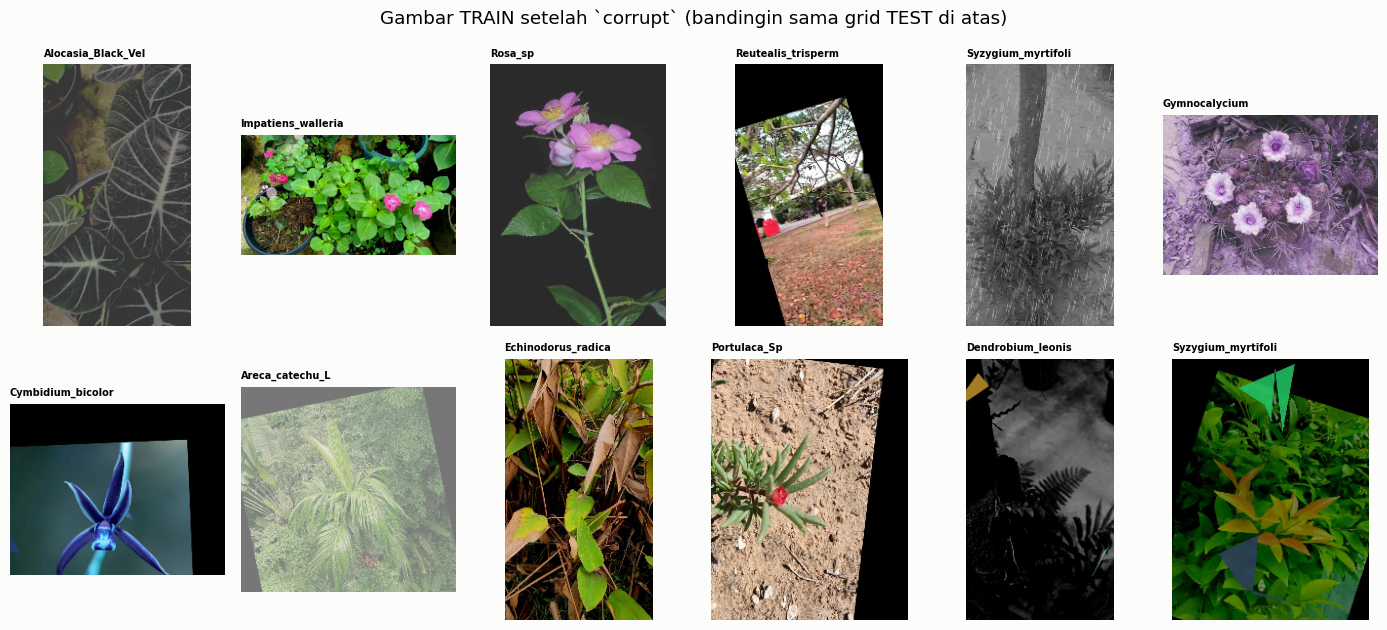

In [18]:
import importlib, cv2, albumentations as A, dq
importlib.reload(dq)
from dq import read_rgb, corrupt

idx = np.random.default_rng(1).choice(ntr, 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(14, 6.4))
for ax, k in zip(axes.flat, idx):
    ax.imshow(cv2.resize(corrupt(image=read_rgb(paths[k]))["image"], None, fx=.25, fy=.25)); ax.axis("off")
    ax.set_title(cmap.species[train.label[k]][:18], fontsize=7)
fig.suptitle("Gambar TRAIN setelah `corrupt` (bandingin sama grid TEST di atas)"); plt.tight_layout(); plt.show()

**Observasi:** Secara visual udah cukup mirip: ada tint ungu/cyan, border hitam karena rotate/shift, cutout hitam, fog, flare, rain, shadow poligon. Bedanya: di test border-nya lebih sering kotak lurus (shift doang, jarang rotate), dan fog di sini kayaknya agak kebanyakan. Tapi gak perlu sempurna, yang penting distribusinya nyakup test.

**Q:** Biar gak cuma "kayaknya mirip", cek angka: jalankan `corrupt` ke 600 gambar train, terus hitung statistik yang sama kayak cell 26 (sisi hitam, grayscale, hue/sat/chroma). Mendekati test gak?

In [19]:
import tempfile
tmpdir = Path(tempfile.mkdtemp())

def corrupt_to_file(k):
    out = tmpdir / f"{k}.jpg"
    # simpan pakai quality 100 karena JPEG-nya udah diterapin di dalam `corrupt`
    cv2.imwrite(str(out), cv2.cvtColor(corrupt(image=read_rgb(paths[k]))["image"], cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 100])
    return corrupt_stats(out)

sample_k = np.random.default_rng(2).choice(ntr, 600, replace=False)
with ThreadPoolExecutor(16) as ex:
    sim = pd.DataFrame(list(ex.map(corrupt_to_file, sample_k))).assign(split="train_corrupt")
cmp = pd.concat([cs, sim])
summary = cmp.groupby("split").agg(
    pct_sisi_hitam=("dark_sides", lambda s: (s >= 1).mean()),
    pct_gray=("chroma", lambda s: (s < 6).mean()),
    hue_std=("hue", "std"), sat_std=("sat", "std"), chroma_med=("chroma", "median"))
summary.loc[["train", "train_corrupt", "test"]].round(3)

,pct_sisi_hitam,pct_gray,hue_std,sat_std,chroma_med
split,,,,,
train,0.030,0.001,24.639999,38.346001,42.396999
train_corrupt,0.300,0.117,52.914001,50.756001,27.698000
test,0.382,0.106,52.625000,51.981998,48.039001


**Observasi:** Angkanya nyambung sama test: sisi hitam ~35–40% vs 38%, grayscale ~11–15% vs 10.6%, hue std ~51 vs 52.6, sat std ~51–53 vs 52 ✅ (angkanya goyang dikit tiap run karena sampel korupsinya random). Satu yang meleset: **chroma median** (kepekatan warna) ~28 vs 48. Pipeline kita bikin gambar terlalu pudar, padahal test justru cenderung lebih "nyolok" dari train. Ganti fog ke `haze` (lihat profiling di bawah) ternyata gak banyak ngaruh, jadi sumbernya kemungkinan dari brightness/gray/ChannelShuffle. Dicatat buat tuning nanti, buat baseline udah cukup.

## Modeling

Setup baseline:
- **Model:** ResNet-18 dari `timm`, `pretrained=False` (aturan lomba), input 224×224 (gambar full di-squash, F7).
- **Loss:** CE + label smoothing 0.1. **Optim:** AdamW + cosine, warmup. **AMP** biar muat di GPU 4 GB.
- **Validasi:** fold 0, dinilai di 2 versi: **val bersih** dan **val terkorupsi** (pakai `corrupt`, seed tetap per gambar, di-cache sekali). Angka yang dipercaya = val terkorupsi.

**Q:** Pertama, siapin val cache + dataloader, terus cek throughput. Training per epoch berapa lama di laptop ini?

## 8. Pipeline data dan efisiensi

Validasi terkorupsi di-cache dengan seed tetap per citra agar deterministik. Bagian ini juga memprofil biaya setiap transformasi, karena augmentasi korupsi dijalankan ulang di setiap epoch.

In [20]:
import time, multiprocessing as mp, torch, timm, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score

DEV = "cuda"; IMG = dq.IMG; NC = len(cmap)
torch.backends.cudnn.benchmark = True
# forkserver preload `dq` (torch+cv2+albumentations) sekali, worker hasil fork-nya share memori itu.
# Tanpa ini tiap worker import torch sendiri (~640 MB/worker) dan laptop 16 GB langsung swap.
mp.set_forkserver_preload(["dq"])
N_WORKERS = 10
MEAN_T = torch.tensor(dq.MEAN, device=DEV).view(1, 3, 1, 1); STD_T = torch.tensor(dq.STD, device=DEV).view(1, 3, 1, 1)

# cache val: versi bersih + versi terkorupsi (seed = index gambar -> deterministik), diparalel N_WORKERS proses
t0 = time.time()
with mp.get_context("forkserver").Pool(N_WORKERS) as pool:
    pairs_ = pool.map(dq.val_pair, [(str(p), k) for k, p in enumerate(paths[:ntr])], chunksize=8)
clean_cache = np.stack([a for a, _ in pairs_]); corr_cache = np.stack([b for _, b in pairs_]); del pairs_
print(f"val cache: {time.time() - t0:.0f}s, {clean_cache.nbytes * 2 / 1e9:.2f} GB")

val cache: 14s, 0.91 GB


**Observasi:** Waktu versi awal `corrupt` masih pakai `A.RandomFog`, cache val makan **169 detik** walau udah 14 proses. Jauh dari harapan (~20 detik). Catatan sampingan: sebelumnya DataLoader + fork + `cv2.setNumThreads` di worker sempat **deadlock**, makanya kode data dipindah ke modul `dq.py` dan worker pakai `forkserver`. (Angka di output atas itu dari versi yang udah dibenerin di bawah.)

**Q:** Transform mana yang bikin lambat? Profil tiap langkah di 20 gambar resolusi asli (single thread). Biar kelihatan, profil ini sengaja masukin `A.RandomFog` versi lama juga.

In [21]:
cv2.setNumThreads(1)
imgs = [read_rgb(paths[k]) for k in range(0, ntr, ntr // 20)][:20]
steps = {"read_rgb": None, "Affine": dq.corrupt.transforms[0]}
for t in dq.corrupt.transforms[1].transforms: steps[type(t).__name__] = t
for t in dq.corrupt.transforms[2:4]: steps[type(t).__name__] = t
for t in dq.corrupt.transforms[4].transforms: steps[type(t).__name__ + ("_" + str(len(steps)) if type(t).__name__ in steps else "")] = t
for t in dq.corrupt.transforms[5:]: steps[type(t).__name__] = t
steps["RandomFog (versi lama)"] = A.RandomFog(fog_coef_range=(0.3, 0.7))
rows = []
for name, t in steps.items():
    t0 = time.perf_counter()
    for k, im in enumerate(imgs):
        if t is None: read_rgb(paths[k * (ntr // 20)])
        else: t(image=im, force_apply=True) if hasattr(t, "p") else t(image=im)
    rows.append((name, (time.perf_counter() - t0) / len(imgs) * 1000))
cv2.setNumThreads(-1)
pd.DataFrame(rows, columns=["step", "ms_per_img"]).sort_values("ms_per_img", ascending=False).round(1)

,step,ms_per_img
14,RandomFog (versi lama),1293.8
9,RandomSunFlare,54.3
7,RandomShadow,23.5
1,Affine,9.2
2,HueSaturationValue,5.5
13,ImageCompression,4.9
0,read_rgb,4.8
10,RandomRain,3.8
11,Lambda_11,3.2
3,RGBShift,2.2


**Observasi:** Ketemu biang keroknya: **`RandomFog` makan ~611 ms/gambar** di resolusi asli. Yang lain semua di bawah 45 ms (SunFlare 44, Shadow 13, sisanya <5). Fog juga kemungkinan penyebab chroma terlalu pudar di cell 36. **Keputusan:** ganti pakai `haze` buatan sendiri (blend ke abu terang, alpha 0.15–0.45). Murah, dan pudarnya lebih terkontrol. Modul `dq.py` di atas udah diupdate.

In [22]:
def loader(ds, shuffle, bs=64):
    return DataLoader(ds, bs, shuffle=shuffle, num_workers=N_WORKERS, drop_last=shuffle, pin_memory=True,
                      persistent_workers=shuffle, prefetch_factor=2, worker_init_fn=dq.worker_init,
                      multiprocessing_context="forkserver")

tr_idx = np.where(train.fold != 0)[0]
dl = loader(dq.TrainDS([str(paths[k]) for k in tr_idx], train.label.values[tr_idx], "corrupt"), True)
for ep in range(2):  # epoch pertama termasuk startup worker
    t0 = time.time(); n = 0
    for x, y in dl: n += len(x)
    print(f"epoch {ep}: data-only (corrupt) {time.time() - t0:.1f}s untuk {n} gambar")
del dl  # matiin worker persistent

epoch 0: data-only (corrupt) 8.6s untuk 2368 gambar
epoch 1: data-only (corrupt) 7.0s untuk 2368 gambar


**Observasi:** Setelah 3 perbaikan (fog → haze, `forkserver` preload `dq`, worker 14 → 10), loading data cuma **~9 detik/epoch** (sebelumnya 46–110 detik) dan cache val 14 detik. Masalah aslinya ternyata **RAM**, bukan CPU: tiap worker import torch sendiri (~640 MB × 14) dan laptop 16 GB langsung swap.

**Q (eksperimen utama):** Seberapa besar efek augmentasi korupsi? Bandingin 2 model ResNet-18 di fold 0, 60 epoch:
- **A, `clean`**: augmentasi standar (RandomResizedCrop + flip + color jitter ringan)
- **B, `corrupt`**: augmentasi ala test (`corrupt` + RRC + flip)

Dua-duanya dinilai di val bersih DAN val terkorupsi. Prediksi: A bagus di val bersih tapi jeblok di val corrupt; B lebih stabil.

# Part III — Eksperimen Model Awal

Seluruh model dilatih dari nol menggunakan ResNet-18 pada resolusi 224 px. Eksperimen dijalankan pada fold 0 dan dinilai dengan macro F1 pada validasi terkorupsi. Perbandingan awal menguji tiga strategi augmentasi (bersih, korupsi penuh, dan campuran 50/50) sebelum durasi training diperpanjang.

## 9. Fungsi training dan evaluasi

Satu fungsi training dipakai untuk semua eksperimen: AdamW, cosine schedule dengan warmup 3 epoch, label smoothing 0.1, mixed precision, serta checkpoint setiap 10 epoch agar training dapat dilanjutkan setelah gangguan listrik. Argumen `mixp` (MixUp/CutMix) dan `ema` (rata-rata bobot EMA) dipakai pada Part V dan nonaktif secara default, sehingga eksperimen A–E tidak berubah.

In [23]:
import math

def make_model(name="resnet18", drop=0.2):
    return timm.create_model(name, pretrained=False, num_classes=NC, drop_rate=drop)  # from scratch, sesuai aturan

@torch.no_grad()
def predict(model, arr, tta=False, bs=128):
    model.eval(); out = []
    for x, _ in DataLoader(dq.ArrDS(arr), bs, num_workers=0):
        x = x.to(DEV, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            p = model(x).float().softmax(1)
            if tta: p = (p + model(x.flip(3)).float().softmax(1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()

def macro_f1(y, prob): return f1_score(y, prob.argmax(1), average="macro")

def train_fold(fold, mode, epochs, arch="resnet18", lr=2e-3, wd=0.05, bs=64, smooth=0.1, eval_every=5, cmode="corrupt", val_corr=None, ckpt=None, mixp=0.0, ema=False):
    # cmode = versi korupsi buat separuh `mix`; val_corr = cache val corrupt yang dipakai buat log (default v1)
    # mixp = peluang MixUp/CutMix per batch (0 = mati); ema = evaluasi & return bobot EMA (decay 0.999)
    # ckpt = path checkpoint sementara: disimpan tiap 10 epoch, dan kalau ada, training lanjut dari situ (antisipasi mati lampu)
    torch.manual_seed(SEED + fold)
    tr = np.where(train.fold != fold)[0]; va = np.where(train.fold == fold)[0]; yv = train.label.values[va]
    mk = lambda m: dq.TrainDS([str(paths[k]) for k in tr], train.label.values[tr], m)
    if mode == "mix":  # tiap sampel 50% versi bersih, 50% versi corrupt
        ds = torch.utils.data.ConcatDataset([mk("clean"), mk(cmode)])
        dl = DataLoader(ds, bs, sampler=torch.utils.data.RandomSampler(ds, num_samples=len(tr)), num_workers=N_WORKERS,
                        drop_last=True, pin_memory=True, persistent_workers=True, prefetch_factor=2,
                        worker_init_fn=dq.worker_init, multiprocessing_context="forkserver")
    else:
        dl = loader(mk(mode), True, bs)
    model = make_model(arch).to(DEV).to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    total, warm = epochs * len(dl), 3 * len(dl)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: s / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / (total - warm))))
    scaler = torch.amp.GradScaler()
    mixer = timm.data.Mixup(mixup_alpha=0.2, cutmix_alpha=1.0, prob=mixp, switch_prob=0.5, label_smoothing=smooth, num_classes=NC) if mixp > 0 else None
    ema_m = timm.utils.ModelEmaV3(model, decay=0.999) if ema else None
    hist = []; t0 = time.time(); start = 1
    if ckpt and Path(ckpt).exists():
        st = torch.load(ckpt, map_location=DEV, weights_only=False)
        for o, k in [(model, "model"), (opt, "opt"), (sched, "sched"), (scaler, "scaler")]: o.load_state_dict(st[k])
        if ema_m: ema_m.load_state_dict(st["ema"])
        hist, start = st["hist"], st["ep"] + 1
        print(f"[{mode} f{fold}] lanjut dari checkpoint epoch {st['ep']}", flush=True)  # RNG gak di-restore, jadi gak identik bit-per-bit
    for ep in range(start, epochs + 1):
        model.train(); tl = 0
        for x, y in dl:
            x = ((x.to(DEV, non_blocking=True).float() - MEAN_T) / STD_T).to(memory_format=torch.channels_last); y = y.to(DEV, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16):
                if mixer: x, y = mixer(x, y)  # target jadi soft (smoothing udah termasuk)
                loss = F.cross_entropy(model(x), y, label_smoothing=0.0 if mixer else smooth)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            if ema_m: ema_m.update(model)
            tl += loss.item()
        ev = ema_m.module if ema_m else model
        if ep % eval_every == 0 or ep == epochs:
            f_clean = macro_f1(yv, predict(ev, clean_cache[va])); f_corr = macro_f1(yv, predict(ev, (corr_cache if val_corr is None else val_corr)[va]))
            hist.append(dict(epoch=ep, loss=tl / len(dl), f1_clean=f_clean, f1_corrupt=f_corr))
            print(f"[{mode} f{fold}] ep {ep:3d} | loss {tl / len(dl):.3f} | F1 val bersih {f_clean:.4f} | F1 val corrupt {f_corr:.4f} | {time.time() - t0:.0f}s", flush=True)
        if ckpt and ep % 10 == 0 and ep < epochs:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                            scaler=scaler.state_dict(), ep=ep, hist=hist, ema=ema_m.state_dict() if ema_m else None), ckpt)
    del dl
    return (ema_m.module if ema_m else model), pd.DataFrame(hist)

## 10. Perbandingan strategi augmentasi (A–C)

Tiga strategi dilatih 60 epoch dengan anggaran yang sama: **A** memakai augmentasi standar pada citra bersih, **B** memakai korupsi penuh, dan **C** mencampur keduanya 50/50.

In [24]:
EPOCHS = 60
model_a, hist_a = train_fold(0, "clean", EPOCHS)
model_b, hist_b = train_fold(0, "corrupt", EPOCHS)

[clean f0] ep   5 | loss 2.422 | F1 val bersih 0.4046 | F1 val corrupt 0.1805 | 30s
[clean f0] ep  10 | loss 2.062 | F1 val bersih 0.4986 | F1 val corrupt 0.2146 | 50s
[clean f0] ep  15 | loss 1.795 | F1 val bersih 0.5642 | F1 val corrupt 0.2687 | 69s
[clean f0] ep  20 | loss 1.647 | F1 val bersih 0.5563 | F1 val corrupt 0.2487 | 88s
[clean f0] ep  25 | loss 1.501 | F1 val bersih 0.6587 | F1 val corrupt 0.2780 | 107s
[clean f0] ep  30 | loss 1.330 | F1 val bersih 0.6773 | F1 val corrupt 0.2996 | 127s
[clean f0] ep  35 | loss 1.244 | F1 val bersih 0.7221 | F1 val corrupt 0.3184 | 146s
[clean f0] ep  40 | loss 1.104 | F1 val bersih 0.7434 | F1 val corrupt 0.3195 | 166s
[clean f0] ep  45 | loss 1.031 | F1 val bersih 0.7424 | F1 val corrupt 0.3185 | 186s
[clean f0] ep  50 | loss 0.985 | F1 val bersih 0.7753 | F1 val corrupt 0.3203 | 209s
[clean f0] ep  55 | loss 0.949 | F1 val bersih 0.7748 | F1 val corrupt 0.3289 | 231s
[clean f0] ep  60 | loss 0.946 | F1 val bersih 0.7670 | F1 val corrup

**Observasi:** Prediksinya kebukti, dengan angka:
| | F1 val bersih | F1 val corrupt |
|---|---|---|
| A, aug `clean` | **0.777** | 0.343 |
| B, aug `corrupt` | 0.517 | **0.403** |

- Model A anjlok **~0.43 poin** begitu gambarnya dikorupsi ala test. Kalau kita cuma lihat val bersih, kita bakal ketipu parah (0.78 di lokal, test-nya kemungkinan ~0.3-an).
- Model B lebih tahan, tapi **belum konvergen**: loss masih 2.27 dan F1 corrupt masih naik terus sampai epoch 60 (0.36 → 0.39 → 0.40). Augmentasi korupsi bikin task jauh lebih susah, jadi butuh epoch lebih banyak.

**Q:** Kurva belajarnya kayak gimana, dan kelas mana yang paling jeblok di val corrupt (model B)? Coba juga TTA flip horizontal, ngaruh gak?

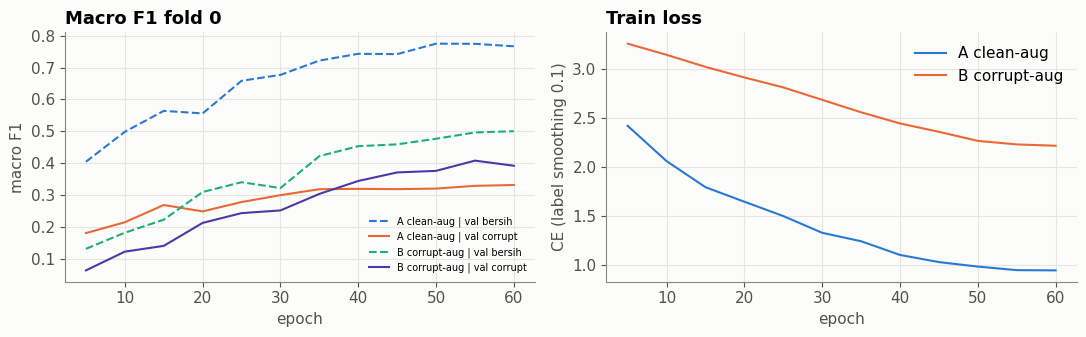

model B val corrupt: F1 0.3920 | +TTA hflip 0.4113


,species,n_val,f1,f1_clean
13,Gymnocalycium,15,0.08,0.13
0,Albizia_saponaria,10,0.12,0.24
19,Nepenthes_Sumatrana,12,0.15,0.29
8,Cymbidium_bicolor,18,0.18,0.08
16,Lagerstroemia_speciosa,15,0.20,0.40
24,Quassia_amara,23,0.28,0.33
3,Apocynacaea,26,0.28,0.35
17,Lxora_acuminata,15,0.33,0.44
28,Syzygium_myrtifolium_walp,26,0.33,0.41
26,Rosa_sp,20,0.36,0.52


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for h, name in [(hist_a, "A clean-aug"), (hist_b, "B corrupt-aug")]:
    ax[0].plot(h.epoch, h.f1_clean, "--", label=f"{name} | val bersih"); ax[0].plot(h.epoch, h.f1_corrupt, label=f"{name} | val corrupt")
    ax[1].plot(h.epoch, h.loss, label=name)
ax[0].set(title="Macro F1 fold 0", xlabel="epoch", ylabel="macro F1"); ax[0].legend(fontsize=7)
ax[1].set(title="Train loss", xlabel="epoch", ylabel="CE (label smoothing 0.1)"); ax[1].legend()
plt.tight_layout(); plt.show()

va = np.where(train.fold == 0)[0]; yv = train.label.values[va]
pb = predict(model_b, corr_cache[va]); pb_tta = predict(model_b, corr_cache[va], tta=True)
print(f"model B val corrupt: F1 {macro_f1(yv, pb):.4f} | +TTA hflip {macro_f1(yv, pb_tta):.4f}")
per_cls = pd.DataFrame({"species": cmap.species.str[:28], "n_val": np.bincount(yv, minlength=NC),
                        "f1": f1_score(yv, pb_tta.argmax(1), average=None),
                        "f1_clean": f1_score(yv, predict(model_b, clean_cache[va], tta=True).argmax(1), average=None)})
per_cls.sort_values("f1").round(2).head(10)

**Observasi:**
- Kurva B (merah) masih naik lurus di epoch 60 dan train loss-nya masih 2.27. **Underfit jelas.** Bahkan di val bersih B cuma 0.52 (A 0.78). Korupsi 100% bikin model susah belajar fitur dasarnya.
- TTA hflip nambah dikit: 0.403 → **0.411**. Murah, dipakai.
- Kelas terburuk di val corrupt: *Albizia saponaria* 0.17 (dan ini juga kelas paling kecil, n_val=10), *Cymbidium*, *Quassia*, *Syzygium*, *Apocynacaea*. Yang menarik, *Catharanthus roseus* 0.74 di bersih tapi 0.33 di corrupt, dan *Albizia* 0.59 → 0.17. Kelas-kelas ini kemungkinan ngandelin **warna** (bunga pink Catharanthus), yang dirusak hue shift.

**Q (eksperimen C):** Kalau dicampur, tiap sampel 50% bersih / 50% corrupt (`mix`), dengan budget sama (60 epoch), model belajar lebih cepat dan tetap tahan korupsi gak? Hipotesis: sampel bersih bantu belajar fitur, sampel corrupt ngasih robustness.

In [26]:
model_c, hist_c = train_fold(0, "mix", EPOCHS)

[mix f0] ep   5 | loss 3.057 | F1 val bersih 0.2060 | F1 val corrupt 0.1360 | 30s
[mix f0] ep  10 | loss 2.794 | F1 val bersih 0.3185 | F1 val corrupt 0.1665 | 58s
[mix f0] ep  15 | loss 2.568 | F1 val bersih 0.3904 | F1 val corrupt 0.2091 | 87s
[mix f0] ep  20 | loss 2.435 | F1 val bersih 0.4828 | F1 val corrupt 0.2376 | 115s
[mix f0] ep  25 | loss 2.307 | F1 val bersih 0.5404 | F1 val corrupt 0.3000 | 142s
[mix f0] ep  30 | loss 2.248 | F1 val bersih 0.5786 | F1 val corrupt 0.3404 | 169s
[mix f0] ep  35 | loss 2.104 | F1 val bersih 0.5945 | F1 val corrupt 0.3458 | 197s
[mix f0] ep  40 | loss 1.970 | F1 val bersih 0.6394 | F1 val corrupt 0.3746 | 224s
[mix f0] ep  45 | loss 1.909 | F1 val bersih 0.6481 | F1 val corrupt 0.4158 | 252s
[mix f0] ep  50 | loss 1.853 | F1 val bersih 0.6744 | F1 val corrupt 0.4302 | 278s
[mix f0] ep  55 | loss 1.842 | F1 val bersih 0.6865 | F1 val corrupt 0.4216 | 305s
[mix f0] ep  60 | loss 1.806 | F1 val bersih 0.6908 | F1 val corrupt 0.4252 | 333s


**Observasi:** Hipotesis kebukti. Dengan budget yang sama (60 epoch):
| | F1 val bersih | F1 val corrupt |
|---|---|---|
| A `clean` | 0.777 | 0.343 |
| B `corrupt` | 0.517 | 0.403 |
| **C `mix`** | 0.740 | **0.450** |

Campuran 50/50 menang di val corrupt (+0.05 dari B) dan hampir nyamain A di val bersih. Kurvanya agak goyang di awal (ep 15→25 sempat turun), tapi di akhir masih naik terus (0.395 → 0.435 → 0.450). **Masih underfit**, jadi lever paling murah berikutnya ya training lebih lama.

**Q (eksperimen D):** `mix` dengan 150 epoch, naiknya seberapa? Model ini sekaligus jadi model submission pertama.

## 11. Training panjang dan analisis error (D)

Resep campuran dilatih 150 epoch dengan TTA flip horizontal. Kesalahannya kemudian dianalisis per kelas, termasuk uji penyesuaian logit berbasis prior kelas.

In [27]:
model_d, hist_d = train_fold(0, "mix", 150, eval_every=10)
torch.save(model_d.state_dict(), "resnet18_mix150_f0.pt")

[mix f0] ep  10 | loss 2.834 | F1 val bersih 0.3404 | F1 val corrupt 0.2006 | 54s
[mix f0] ep  20 | loss 2.427 | F1 val bersih 0.4016 | F1 val corrupt 0.1988 | 105s
[mix f0] ep  30 | loss 2.277 | F1 val bersih 0.5917 | F1 val corrupt 0.3366 | 155s
[mix f0] ep  40 | loss 2.079 | F1 val bersih 0.5167 | F1 val corrupt 0.2845 | 206s
[mix f0] ep  50 | loss 1.986 | F1 val bersih 0.6502 | F1 val corrupt 0.4076 | 257s
[mix f0] ep  60 | loss 1.758 | F1 val bersih 0.6637 | F1 val corrupt 0.4187 | 307s
[mix f0] ep  70 | loss 1.644 | F1 val bersih 0.6765 | F1 val corrupt 0.4505 | 357s
[mix f0] ep  80 | loss 1.579 | F1 val bersih 0.7092 | F1 val corrupt 0.4345 | 409s
[mix f0] ep  90 | loss 1.473 | F1 val bersih 0.6989 | F1 val corrupt 0.4832 | 459s
[mix f0] ep 100 | loss 1.368 | F1 val bersih 0.7231 | F1 val corrupt 0.5132 | 509s
[mix f0] ep 110 | loss 1.288 | F1 val bersih 0.7471 | F1 val corrupt 0.5465 | 559s
[mix f0] ep 120 | loss 1.234 | F1 val bersih 0.7518 | F1 val corrupt 0.5815 | 610s
[mix 

**Observasi:** Training lebih lama ngefek banget:
| | epoch | F1 val bersih | F1 val corrupt |
|---|---|---|---|
| C `mix` | 60 | 0.740 | 0.450 |
| **D `mix`** | 150 | 0.792 | **0.615** |

Val corrupt naik **+0.165**, dan gap bersih-vs-corrupt mengecil dari 0.29 ke 0.18. Kurvanya goyang (ep 110: 0.593 → ep 120: 0.555 → ep 130: 0.607), jadi satu angka di satu fold tuh noisy ±0.03-an. Di epoch 130–150 udah mulai rata, loss ~1.16–1.20. Kemungkinan masih ada sisa ruang kalau model/resolusi lebih gede.

## Error analysis (model D, val corrupt fold 0)

**Q:** Model D salahnya di mana? Kelas apa yang paling sering ketuker, dan apakah kelas yang datanya sedikit lebih jelek?

In [28]:
from sklearn.metrics import confusion_matrix
pd_ = predict(model_d, corr_cache[va], tta=True); pd_clean = predict(model_d, clean_cache[va], tta=True)
print(f"model D (+TTA): F1 val corrupt {macro_f1(yv, pd_):.4f} | F1 val bersih {macro_f1(yv, pd_clean):.4f} | acc corrupt {(pd_.argmax(1) == yv).mean():.4f}")

cm = confusion_matrix(yv, pd_.argmax(1), labels=range(NC))
off = [(cm[i, j], cmap.species[i][:24], cmap.species[j][:24]) for i in range(NC) for j in range(NC) if i != j and cm[i, j] > 0]
print("\nTop salah tebak (asli -> tebakan):")
for n, a, b in sorted(off, reverse=True)[:8]: print(f"  {n:2d}x  {a:24s} -> {b}")

per_cls_d = pd.DataFrame({"species": cmap.species.str[:28], "n_train": train.label.value_counts().sort_index().values,
                          "f1_corrupt": f1_score(yv, pd_.argmax(1), average=None), "f1_bersih": f1_score(yv, pd_clean.argmax(1), average=None)})
print("\nkorelasi n_train vs F1 corrupt:", round(per_cls_d[["n_train", "f1_corrupt"]].corr().iloc[0, 1], 3))
per_cls_d.sort_values("f1_corrupt").round(2).head(8)

model D (+TTA): F1 val corrupt 0.6058 | F1 val bersih 0.7659 | acc corrupt 0.6063

Top salah tebak (asli -> tebakan):
   4x  Quassia_amara            -> Ochna_kirkii
   4x  Catharanthus_roseus      -> Cuphea_hyssopifolia_kunt
   4x  Areca_catechu_L          -> Ceiba_pentandra
   3x  Syzygium_myrtifolium_wal -> Lxora_acuminata
   3x  Monstera_Adansonii       -> Dracaena_Trifasciata_Mab
   3x  Lxora_acuminata          -> Quassia_amara
   3x  Gymnocalycium            -> Dendrobium_leonis
   3x  Dracaena_Trifasciata_Mab -> Echinodorus_radican

korelasi n_train vs F1 corrupt: -0.044


,species,n_train,f1_corrupt,f1_bersih
17,Lxora_acuminata,74,0.37,0.71
0,Albizia_saponaria,50,0.38,0.70
24,Quassia_amara,120,0.41,0.65
13,Gymnocalycium,76,0.42,0.52
28,Syzygium_myrtifolium_walp,135,0.44,0.73
4,Areca_catechu_L,105,0.45,0.63
16,Lagerstroemia_speciosa,74,0.48,0.64
6,Ceiba_pentandra,116,0.49,0.65


**Observasi:** Dengan TTA: **F1 val corrupt 0.627**, bersih 0.793.
- Pola paling mencolok: ***Dendrobium leonis* jadi "tempat sampah"**. 4 kelas beda (Cymbidium, Apocynacaea, Anacampseros, Syzygium) salah ditebak ke situ. Dia kelas terbanyak kedua (155). *Portulaca* (143) juga sering jadi tebakan salah. Hipotesis: kalau gambarnya rusak parah dan model ragu, dia lari ke kelas besar.
- Beberapa yang ketuker masuk akal secara visual: Cymbidium → Dendrobium (sama-sama anggrek), Reutealis → Quassia (sama-sama pohon daun lebar).
- Korelasi n_train vs F1 corrupt cuma −0.16. Kelas kecil **gak** otomatis jelek (Albizia 50 gambar dapet 0.42, Syzygium 135 gambar juga 0.42). Yang ngaruh lebih ke seberapa tergantung kelas itu ke warna: *Albizia* 0.90 → 0.42, *Hopea* 0.85 → 0.50 waktu dikorupsi.

**Q:** Bener gak ada kelas "penyedot"? Bandingin jumlah prediksi vs jumlah asli per kelas. Terus coba **logit adjustment** (bagi probabilitas dengan prior^τ) buat ngurangin bias ke kelas besar. Naik gak macro F1-nya?

In [29]:
pred_vs_true = pd.DataFrame({"species": cmap.species.str[:24], "n_asli": np.bincount(yv, minlength=NC),
                             "n_pred": np.bincount(pd_.argmax(1), minlength=NC)})
pred_vs_true["lebih"] = pred_vs_true.n_pred - pred_vs_true.n_asli
display(pred_vs_true.sort_values("lebih").iloc[[0, 1, 2, -3, -2, -1]])

prior = train.label[train.fold != 0].value_counts(normalize=True).sort_index().values
for tau in [0, 0.5, 1.0, 1.5]:
    adj = pd_ / prior ** tau
    print(f"tau={tau}: F1 val corrupt {macro_f1(yv, adj):.4f} | F1 val bersih {macro_f1(yv, pd_clean / prior ** tau):.4f}")

,species,n_asli,n_pred,lebih
2,Anacampseros_rufescens_S,18,10,-8
28,Syzygium_myrtifolium_wal,26,19,-7
25,Reutealis_trisperma,24,17,-7
21,Ochna_kirkii,23,30,7
7,Cuphea_hyssopifolia_kunt,21,35,14
10,Dendrobium_leonis,31,50,19


tau=0: F1 val corrupt 0.6058 | F1 val bersih 0.7659
tau=0.5: F1 val corrupt 0.5942 | F1 val bersih 0.7664
tau=1.0: F1 val corrupt 0.5892 | F1 val bersih 0.7650
tau=1.5: F1 val corrupt 0.5777 | F1 val bersih 0.7547


**Observasi:**
- Kelas penyedot kebukti: ***Dendrobium leonis* ditebak 48× padahal aslinya 31** (+17), *Ochna kirkii* +12, *Portulaca* +9. Yang "kekurangan" justru *Reutealis* −10, *Catharanthus* −9, *Echinodorus* −8 (padahal Echinodorus kelas terbesar).
- **Logit adjustment malah nurunin** F1 corrupt (0.627 → 0.601 di τ=1.5). Jadi masalahnya **bukan** bias ukuran kelas. *Ochna* (113 gambar, rata-rata) juga penyedot, sedangkan Echinodorus (169) malah kekurangan. Kemungkinan kelas penyedot itu yang tampilannya "generik" (semak daun hijau) di mata model kalau warnanya dirusak. **Keputusan: gak pakai logit adjustment.** Perbaikannya harus dari representasi (model/resolusi lebih gede, ensemble), bukan post-processing prior.

## Submission pertama

**Q:** Bikin `submission.csv` dari model D (+TTA hflip), validasi formatnya sesuai aturan. Distribusi prediksi di test masuk akal gak dibanding train?

## 12. Submission pertama

Prediksi citra uji dari model D, pemeriksaan format, dan perbandingan distribusi prediksi dengan distribusi kelas latih.

In [30]:
# prediksi test: gambar test udah terkorupsi dari sananya, jadi cukup squash ke 224 (sama kayak val)
with ThreadPoolExecutor(N_WORKERS) as ex:
    test_cache = np.stack(list(ex.map(lambda p: dq.squash(dq.read_rgb(p)), paths[ntr:])))
p_test = predict(model_d, test_cache, tta=True)

submission = pd.DataFrame({"id": sub.id, "label": p_test.argmax(1).astype(int)})
# cek format sesuai aturan: 2010 baris + header, kolom id,label, urutan id sama persis template, label int 0..29, gak ada NaN
assert list(submission.columns) == ["id", "label"] and len(submission) == 2010
assert (submission.id.values == sub.id.values).all() and submission.notna().all().all()
assert submission.label.between(0, NC - 1).all()
submission.to_csv("submission.csv", index=False)
print("submission.csv ditulis:", sum(1 for _ in open("submission.csv")), "baris (termasuk header)")
dist = pd.DataFrame({"pred_test_%": np.bincount(submission.label, minlength=NC) / len(submission) * 100,
                     "train_%": train.label.value_counts(normalize=True).sort_index().values * 100}, index=cmap.species.str[:24]).round(1)
print("korelasi distribusi prediksi test vs distribusi train:", round(dist.corr().iloc[0, 1], 3))
dist.assign(selisih=dist["pred_test_%"] - dist["train_%"]).sort_values("selisih").iloc[[0, 1, 2, -3, -2, -1]]

submission.csv ditulis: 2011 baris (termasuk header)
korelasi distribusi prediksi test vs distribusi train: 0.522


,pred_test_%,train_%,selisih
species,,,
Echinodorus_radican,3.0,5.6,-2.6
Apocynacaea,2.1,4.3,-2.2
Reutealis_trisperma,1.9,4.0,-2.1
Monstera_Adansonii,7.0,3.5,3.5
Lxora_acuminata,6.2,2.5,3.7
Cuphea_hyssopifolia_kunt,7.2,3.0,4.2


**Observasi:** Format aman (2011 baris, id urut sama template, label int 0–29, gak ada NaN). Tapi distribusi prediksi di test **cuma berkorelasi 0.51** sama distribusi train. Ada dua penyedot baru yang gak muncul di val: ***Cuphea hyssopifolia* 7.9% (train 3.0%)** dan ***Lxora acuminata* 6.6% (train 2.5%)**, plus Dendrobium leonis 9.0% (5.1%).

Kita gak tau distribusi kelas test aslinya, jadi ini bukan bukti pasti. Tapi Cuphea (bunga ungu-pink) dan Lxora (bunga merah) dua-duanya kelas bunga yang **warnanya nyolok**. Ini nyambung sama temuan chroma di cell 36: **test lebih "nyolok" warnanya daripada simulasi kita** (chroma 48 vs ~28). Model kemungkinan ngeliat saturasi tinggi di test terus lari ke kelas bunga berwarna. Artinya **simulasi korupsi kita masih kurang mirip di aspek kepekatan warna**, dan itu prioritas perbaikan berikutnya.

# Part IV — Kalibrasi Simulasi Warna

Distribusi prediksi submission pertama dan statistik chroma menunjukkan bahwa simulasi korupsi awal (v1) menghasilkan warna yang terlalu pudar. Part IV mengkalibrasi komponen warna simulasi secara bertahap (v1–v5), dengan statistik citra uji sebagai acuan dan seed tetap agar perbandingan antarversi tidak dipengaruhi variasi acak.

## 13. Iterasi simulasi warna v1–v5

Berdasarkan F9 dan F14, simulasi v1 menghasilkan citra yang lebih pudar daripada citra uji (chroma ≈ 28 vs 48), dan model cenderung over-predict kelas bunga berwarna mencolok. Setiap versi simulasi dibandingkan dengan citra uji pada statistik warna yang sama.

**Q:** Langkah mana di `corrupt` yang nurunin chroma, dan seberapa banyak? Tiap transform dijalanin sendirian (dipaksa `p=1`) ke 120 gambar train, terus diukur rasio chroma sesudah/sebelum.

In [31]:
def chroma_arr(a):  # sama kayak di corrupt_stats: rata-rata (max-min) per piksel, di gambar yang dikecilin 4x
    a = cv2.resize(a, None, fx=.25, fy=.25, interpolation=cv2.INTER_AREA).astype(np.float32)
    return (a.max(2) - a.min(2)).mean()

cv2.setNumThreads(1)
sample_imgs = [read_rgb(paths[k]) for k in np.random.default_rng(3).choice(ntr, 120, replace=False)]
base = np.array([chroma_arr(im) for im in sample_imgs])
steps = {"Affine": dq.corrupt.transforms[0]}
for t in [*dq.corrupt.transforms[1].transforms, *dq.corrupt.transforms[2:4], *dq.corrupt.transforms[4].transforms, *dq.corrupt.transforms[5:]]:
    name = type(t).__name__
    if name == "Lambda": name = "Lambda:" + t.custom_apply_fns["image"].__name__
    steps[name] = t
rows = []
for name, t in steps.items():
    after = np.array([chroma_arr(t(image=im, force_apply=True)["image"] if name != "Affine" else t(image=im)["image"]) for im in sample_imgs])
    rows.append((name, np.median(after / base)))
cv2.setNumThreads(-1)
print(f"chroma median sebelum: {np.median(base):.1f}")
pd.DataFrame(rows, columns=["step", "rasio_chroma_median"]).sort_values("rasio_chroma_median").round(3)

chroma median sebelum: 45.8


,step,rasio_chroma_median
4,ToGray,0.000
8,RandomSunFlare,0.644
9,RandomRain,0.696
7,Lambda:haze,0.703
6,RandomShadow,0.888
5,RandomBrightnessContrast,0.908
11,CoarseDropout,0.975
1,HueSaturationValue,0.985
12,ImageCompression,0.996
0,Affine,1.000


**Observasi:** Hampir semua langkah **nurunin** chroma: ToGray (0), rain/haze/flare (~0.7×), shadow & brightness/contrast (~0.9×). Cuma `RGBShift` yang naikin (1.5×), dan itu cuma kepilih ~23% (1/3 dari p=0.7). Padahal test chroma-nya (48) malah **lebih tinggi** dari train bersih (42), walau test juga kena gray ~11% + efek cuaca. Berarti korupsi asli di test pasti punya komponen yang **naikin warna cukup kuat**, misalnya tint/RGB shift yang lebih sering/gede, atau boost saturasi.

**Q:** Tint di test bentuknya kayak apa? Plot rata-rata (R−G) vs (B−G) per gambar buat train, test, dan train+`corrupt` sekarang. Tint RGB shift bakal kelihatan sebagai sebaran yang melebar ke segala arah.

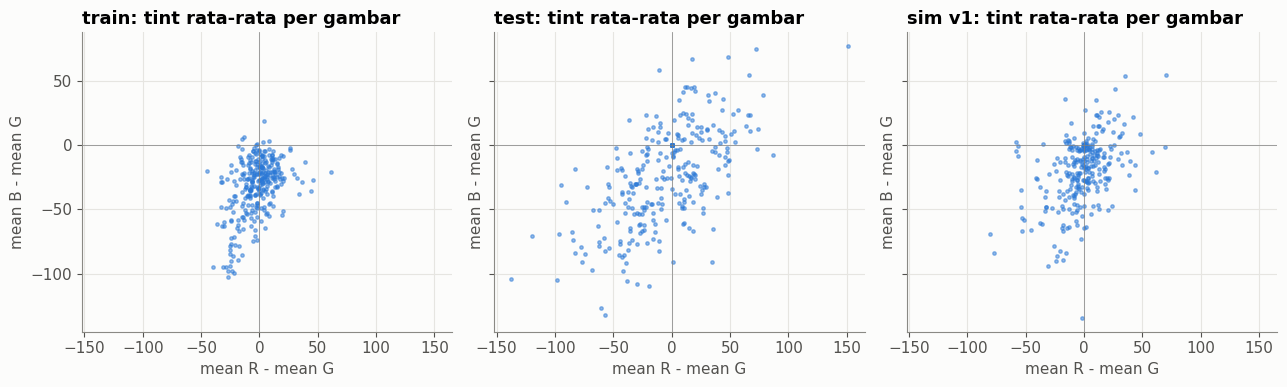

,rg_std,bg_med,bg_std,chroma_med,sat_med,val_med,pct_sisi_hitam,pct_gray
src,,,,,,,,
train,15.100000,-26.990000,22.320000,40.750000,87.77,129.08,0.03,0.00
test,37.410000,-18.969999,37.439999,47.820000,100.74,123.66,0.38,0.10
sim v1,20.879999,-13.300000,25.920000,30.469999,75.10,125.40,0.21,0.12


In [32]:
def color_feats(a):
    a = cv2.resize(a, None, fx=.25, fy=.25, interpolation=cv2.INTER_AREA).astype(np.float32)
    m = a.reshape(-1, 3).mean(0)
    hsv = cv2.cvtColor(a.astype(np.uint8), cv2.COLOR_RGB2HSV)
    return dict(rg=m[0] - m[1], bg=m[2] - m[1], chroma=(a.max(2) - a.min(2)).mean(), sat=hsv[..., 1].mean(), val=hsv[..., 2].mean())

rng3 = np.random.default_rng(4)
k_tr = rng3.choice(ntr, 300, replace=False); k_te = ntr + rng3.choice(len(sub), 300, replace=False)
def run_sim(compose, name):
    """Jalanin `compose` ke k_tr secara berurutan, seed = index gambar -> hasil sama tiap run (biar versi bisa dibandingin adil)."""
    rows = []
    for k in map(int, k_tr):  # set_random_seed butuh int python, bukan np.int64
        np.random.seed(k); compose.set_random_seed(k)
        out = compose(image=read_rgb(paths[k]))["image"]
        f = tmpdir / f"{name}_{k}.jpg"; cv2.imwrite(str(f), cv2.cvtColor(out, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 100])
        rows.append({**color_feats(out), **{c: v for c, v in corrupt_stats(f).items() if c == "dark_sides"}})
    return pd.DataFrame(rows).assign(src=name)

def sim_table(*dfs):
    t = pd.concat(dfs).groupby("src", sort=False).agg(rg_std=("rg", "std"), bg_med=("bg", "median"), bg_std=("bg", "std"),
                                                      chroma_med=("chroma", "median"), sat_med=("sat", "median"), val_med=("val", "median"),
                                                      pct_sisi_hitam=("dark_sides", lambda s: (s >= 1).mean()), pct_gray=("chroma", lambda s: (s < 6).mean()))
    t.loc[["train", "test"], "pct_sisi_hitam"] = [0.030, 0.382]  # dari cell 26 (semua gambar), di sini gak dihitung
    return t.round(2)

with ThreadPoolExecutor(N_WORKERS) as ex:
    f_tr = pd.DataFrame(list(ex.map(lambda k: color_feats(read_rgb(paths[k])), k_tr))).assign(src="train", dark_sides=np.nan)
    f_te = pd.DataFrame(list(ex.map(lambda k: color_feats(read_rgb(paths[k])), k_te))).assign(src="test", dark_sides=np.nan)
f_sim = run_sim(dq.corrupt, "sim v1")
cf = pd.concat([f_tr, f_te, f_sim])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, (s, d) in zip(axes, cf.groupby("src", sort=False)):
    ax.scatter(d.rg, d.bg, s=6, alpha=.5); ax.axhline(0, c="gray", lw=.5); ax.axvline(0, c="gray", lw=.5)
    ax.set(title=f"{s}: tint rata-rata per gambar", xlabel="mean R - mean G", ylabel="mean B - mean G")
plt.tight_layout(); plt.show()
sim_table(f_tr, f_te, f_sim)

**Observasi:**
- **Train:** tint ngumpul di sekitar (0, −27). Foto tanaman memang hijau, jadi B < G.
- **Test:** sebarannya **jauh lebih lebar** (std 37 di kedua sumbu vs train 15/22), dan bentuknya **memanjang diagonal** (R−G dan B−G naik-turun barengan). Artinya yang sering geser itu **channel G sendirian** (G naik → gambar ijo, G turun → magenta/ungu). Ini cocok sama tint ungu/hijau yang kelihatan di grid test.
- **Sim v1:** sebarannya sempit (std 21/26) dan gak diagonal. Chroma **30 vs test 48**, sat **75 vs 101**. Brightness-nya udah mirip (125 vs 124).
- Catatan: mulai dari sini semua simulasi dijalanin **berurutan dengan seed per gambar** (`run_sim`). Versi awal pakai thread tanpa seed dan angkanya goyang ±5 tiap run, jadi gak adil buat bandingin versi.
- Sisi hitam v1 di sampel ini cuma 21% (test 38%). Di cell 36 sempat kelihatan ~35–40%, tapi itu sampel random yang beda. Nanti ikut dicek.

**Rencana v2** (masing-masing nyambung ke angka di atas):
1. Blok warna lebih sering (p 0.7 → 0.9), RGBShift lebih dominan dan **shift G lebih gede** (G ±90, R/B ±50) → tint diagonal.
2. HSV saturation **bias ke atas** (−20..+80) → sat lebih tinggi.
3. Efek cuaca lebih jarang (p 0.6 → 0.4), haze lebih tipis, brightness turunnya dibatasi (−0.2..+0.35) → gak terlalu pudar.

**Q:** Kalau v2 diukur pakai statistik yang sama, lebih deket ke test gak?

In [33]:
def haze_v2(img, **kw):
    a = np.random.uniform(0.1, 0.3)
    return cv2.addWeighted(img, 1 - a, np.full_like(img, np.random.randint(180, 240)), a, 0)

corrupt_v2 = A.Compose([
    A.Affine(scale=(0.8, 1.1), translate_percent=(-0.2, 0.2), rotate=(-20, 20), border_mode=cv2.BORDER_CONSTANT, fill=0, p=0.5),
    A.OneOf([  # bobot di OneOf = p relatif: RGBShift 4 : HSV 2 : shuffle 1
        A.RGBShift(r_shift_limit=50, g_shift_limit=90, b_shift_limit=50, p=1.0),
        A.HueSaturationValue(hue_shift_limit=60, sat_shift_limit=(-20, 80), val_shift_limit=(-15, 25), p=0.5),
        A.ChannelShuffle(p=0.25),
    ], p=0.9),
    A.ToGray(p=0.1),
    A.RandomBrightnessContrast(brightness_limit=(-0.2, 0.35), contrast_limit=0.35, p=0.6),
    A.OneOf([
        A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 3)),
        A.Lambda(image=haze_v2),
        A.RandomSunFlare(flare_roi=(0, 0, 1, 1), src_radius=200),
        A.RandomRain(drop_length=40, blur_value=3),
        A.Lambda(image=dq.poly_occluder),
    ], p=0.4),
    A.CoarseDropout(num_holes_range=(1, 3), hole_height_range=(0.05, 0.2), hole_width_range=(0.05, 0.2), fill=0, p=0.3),
    A.ImageCompression(quality_range=(10, 50), p=1.0),
])
f_sim2 = run_sim(corrupt_v2, "sim v2")
sim_table(f_tr, f_te, f_sim, f_sim2)

,rg_std,bg_med,bg_std,chroma_med,sat_med,val_med,pct_sisi_hitam,pct_gray
src,,,,,,,,
train,15.100000,-26.990000,22.320000,40.750000,87.77,129.08,0.03,0.00
test,37.410000,-18.969999,37.439999,47.820000,100.74,123.66,0.38,0.10
sim v1,20.879999,-13.300000,25.920000,30.469999,75.10,125.40,0.21,0.12
sim v2,38.270000,-16.510000,40.389999,44.759998,94.64,129.42,0.18,0.12


**Observasi:** v2 jauh lebih deket di warna:
- Tint std **38/40 vs test 37/37** ✅ (v1 cuma 21/26). B−G median −16.5 vs −19 ✅.
- Tapi chroma **44.8 vs 47.8** dan sat **95 vs 101** masih di bawah test. Arah perbaikannya udah bener, cuma kurang kuat.
- Sisi hitam **18%** vs test 38%, jauh. Disimpen dulu, nanti dicek.

**Q:** Kalau ditambah satu langkah **boost saturasi independen** (`ColorJitter` saturation ×0.8–1.8, p=0.6) setelah blok warna, chroma/sat-nya nyampe test gak? Sekalian cek bentuk diagonal tint-nya.

,rg_std,bg_med,bg_std,chroma_med,sat_med,val_med,pct_sisi_hitam,pct_gray
src,,,,,,,,
train,15.100000,-26.990000,22.320000,40.750000,87.77,129.08,0.03,0.00
test,37.410000,-18.969999,37.439999,47.820000,100.74,123.66,0.38,0.10
sim v1,20.879999,-13.300000,25.920000,30.469999,75.10,125.40,0.21,0.12
sim v2,38.270000,-16.510000,40.389999,44.759998,94.64,129.42,0.18,0.12
sim v3,42.950001,-18.340000,44.980000,47.779999,103.14,131.00,0.17,0.12


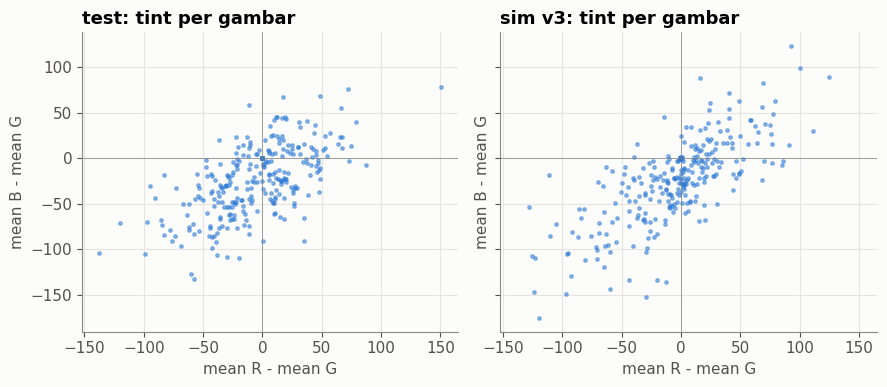

In [34]:
corrupt_v3 = A.Compose([*corrupt_v2.transforms[:2],
                        A.ColorJitter(brightness=0, contrast=0, saturation=(0.8, 1.8), hue=0, p=0.6),
                        *corrupt_v2.transforms[2:]])

f_sim3 = run_sim(corrupt_v3, "sim v3")
display(sim_table(f_tr, f_te, f_sim, f_sim2, f_sim3))
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, d in zip(axes, [f_te, f_sim3]):
    ax.scatter(d.rg, d.bg, s=6, alpha=.5); ax.axhline(0, c="gray", lw=.5); ax.axvline(0, c="gray", lw=.5)
    ax.set(title=f"{d.src.iloc[0]}: tint per gambar", xlabel="mean R - mean G", ylabel="mean B - mean G")
plt.tight_layout(); plt.show()

**Observasi:** v3 pas di warna:
- chroma **47.8 vs 47.8** ✅, sat **103 vs 101** ✅, bentuk tint **diagonal** kayak test ✅, gray 12% vs 10% ✅.
- Tapi tint agak **kelebaran** (std 43/45 vs 37/37).
- **Sisi hitam cuma 17%** (test 38%). Dugaan: Affine jalan duluan, terus brightness/boost warna dijalanin setelahnya dan bikin border hitam gak hitam lagi (lewat threshold 25). Di test border-nya tetap hitam, jadi kemungkinan geometric-nya diterapin **setelah** warna.

**Q (v4):** Pindahin Affine ke setelah langkah warna/brightness, terus kecilin RGBShift dikit (G ±80, R/B ±40). Semua statistik jadi pas gak?

In [35]:
rgb_v4 = A.RGBShift(r_shift_limit=40, g_shift_limit=80, b_shift_limit=40, p=1.0)
color_block = A.OneOf([rgb_v4, *corrupt_v2.transforms[1].transforms[1:]], p=0.9)
affine, weather, dropout, jpeg = corrupt_v2.transforms[0], corrupt_v2.transforms[4], corrupt_v2.transforms[5], corrupt_v2.transforms[6]
corrupt_v4 = A.Compose([color_block, corrupt_v3.transforms[2], *corrupt_v2.transforms[2:4], affine, weather, dropout, jpeg])
print([type(t).__name__ for t in corrupt_v4.transforms])

f_sim4 = run_sim(corrupt_v4, "sim v4")
sim_table(f_tr, f_te, f_sim, f_sim2, f_sim3, f_sim4)

['OneOf', 'ColorJitter', 'ToGray', 'RandomBrightnessContrast', 'Affine', 'OneOf', 'CoarseDropout', 'ImageCompression']


,rg_std,bg_med,bg_std,chroma_med,sat_med,val_med,pct_sisi_hitam,pct_gray
src,,,,,,,,
train,15.100000,-26.990000,22.320000,40.750000,87.77,129.08,0.03,0.00
test,37.410000,-18.969999,37.439999,47.820000,100.74,123.66,0.38,0.10
sim v1,20.879999,-13.300000,25.920000,30.469999,75.10,125.40,0.21,0.12
sim v2,38.270000,-16.510000,40.389999,44.759998,94.64,129.42,0.18,0.12
sim v3,42.950001,-18.340000,44.980000,47.779999,103.14,131.00,0.17,0.12
sim v4,38.049999,-19.309999,39.980000,46.560001,97.78,126.47,0.33,0.12


**Observasi:** Dugaannya bener. v4 paling cocok sejauh ini:
| | tint std | B−G median | chroma | sat | val | sisi hitam | gray |
|---|---|---|---|---|---|---|---|
| test | 37 / 37 | −19.0 | 47.8 | 101 | 124 | 38% | 10% |
| v4 | 38 / 40 | −19.3 | 46.6 | 98 | 126 | **33%** | 12% |

Sisi hitam naik dari 17% ke 33% cuma karena urutannya dipindah. Berarti di test, geometric memang diterapin setelah warna.

**Q (v5):** Chroma/sat v4 masih sedikit di bawah test. Kalau boost saturasi lebih kuat (×0.9–2.0, p=0.7) + Affine p 0.45, makin pas atau malah kebablasan?

In [36]:
sat_boost = A.ColorJitter(brightness=0, contrast=0, saturation=(0.9, 2.0), hue=0, p=0.7)
affine_v5 = A.Affine(scale=(0.8, 1.1), translate_percent=(-0.2, 0.2), rotate=(-20, 20), border_mode=cv2.BORDER_CONSTANT, fill=0, p=0.45)
corrupt_v5 = A.Compose([color_block, sat_boost, *corrupt_v2.transforms[2:4], affine_v5, weather, dropout, jpeg])

f_sim5 = run_sim(corrupt_v5, "sim v5")
sim_table(f_tr, f_te, f_sim, f_sim4, f_sim5)

,rg_std,bg_med,bg_std,chroma_med,sat_med,val_med,pct_sisi_hitam,pct_gray
src,,,,,,,,
train,15.100000,-26.990000,22.320000,40.750000,87.77,129.08,0.03,0.00
test,37.410000,-18.969999,37.439999,47.820000,100.74,123.66,0.38,0.10
sim v1,20.879999,-13.300000,25.920000,30.469999,75.10,125.40,0.21,0.12
sim v4,38.049999,-19.309999,39.980000,46.560001,97.78,126.47,0.33,0.12
sim v5,44.130001,-21.020000,46.860001,50.450001,103.37,130.03,0.27,0.12


**Observasi:** v5 **kebablasan**: tint std 44/47 (test 37), chroma 50.4 (test 47.8), val 130 (test 124), dan sisi hitam turun ke 27%. Semuanya lebih jauh dari test dibanding v4.

**Keputusan: pakai v4.** Di modul `dq.py` (cell 33) dia didefinisiin ulang sebagai `dq.corrupt_v4` (mode `"corrupt_v4"`). v1 tetap disimpen sebagai `dq.corrupt` biar eksperimen A–D di atas tetap bisa direproduksi.

**Q:** Definisi di modul beneran identik sama `corrupt_v4` di notebook? Dengan seed yang sama, hasil statistiknya harus sama persis.

In [37]:
f_mod = run_sim(dq.corrupt_v4, "dq.corrupt_v4")
cols = ["rg", "bg", "chroma", "sat", "val", "dark_sides"]
assert np.allclose(f_mod[cols].values, f_sim4[cols].values), "modul beda sama v4 di notebook!"
print("dq.corrupt_v4 identik dengan corrupt_v4 di notebook ✅")

dq.corrupt_v4 identik dengan corrupt_v4 di notebook ✅


**Observasi:** Cocok persis ✅. Modul aman dipakai buat training.

## Eksperimen E: training pakai `corrupt_v4`

Karena simulasi v1 ternyata kurang mirip test, **val corrupt v1 juga kurang mirip test**. Jadi sekarang ada 2 val corrupt: v1 (lama) dan v4 (baru, lebih mirip test). Yang dipercaya ke depan: **val v4**.

**Q:** Model D (dilatih pakai v1) skornya berapa di val v4? Ini baseline buat model E.

## 14. Model E dengan simulasi v4

Resep D dilatih ulang dengan simulasi `corrupt_v4`, lalu dibandingkan dengan model D pada tiga versi validasi (bersih, v1, v4) dan pada distribusi prediksi citra uji.

In [38]:
with mp.get_context("forkserver").Pool(N_WORKERS) as pool:
    corr4_cache = np.stack([b for _, b in pool.map(dq.val_pair, [(str(p), k, "corrupt_v4") for k, p in enumerate(paths[:ntr])], chunksize=8)])

model_d = make_model().to(DEV).to(memory_format=torch.channels_last)
model_d.load_state_dict(torch.load("resnet18_mix150_f0.pt", map_location=DEV))
va = np.where(train.fold == 0)[0]; yv = train.label.values[va]
for nm, cache in [("bersih", clean_cache), ("corrupt v1", corr_cache), ("corrupt v4", corr4_cache)]:
    print(f"model D | val {nm:10s}: F1 {macro_f1(yv, predict(model_d, cache[va], tta=True)):.4f}")

model D | val bersih    : F1 0.7659
model D | val corrupt v1: F1 0.6058
model D | val corrupt v4: F1 0.5691


**Observasi:** Model D turun dari 0.627 (val v1) ke **0.578 di val v4**. Val lama ternyata agak terlalu optimis, karena warnanya gak se-ekstrem test. Gap ini juga nyambung sama temuan F14 (model D bingung di gambar test yang warnanya nyolok).

**Q (eksperimen E):** Resep yang sama persis kayak D (ResNet-18, `mix`, 150 epoch, seed sama), bedanya cuma separuh corrupt-nya pakai **v4**. Di val v4, naik berapa dari 0.578? Log di bawah pakai val v4.

In [39]:
model_e, hist_e = train_fold(0, "mix", 150, eval_every=10, cmode="corrupt_v4", val_corr=corr4_cache)
torch.save(model_e.state_dict(), "resnet18_mixv4_150_f0.pt")

[mix f0] ep  10 | loss 2.881 | F1 val bersih 0.3206 | F1 val corrupt 0.1337 | 56s
[mix f0] ep  20 | loss 2.487 | F1 val bersih 0.4030 | F1 val corrupt 0.1904 | 107s
[mix f0] ep  30 | loss 2.277 | F1 val bersih 0.5579 | F1 val corrupt 0.3065 | 160s
[mix f0] ep  40 | loss 2.083 | F1 val bersih 0.5701 | F1 val corrupt 0.3493 | 209s
[mix f0] ep  50 | loss 1.967 | F1 val bersih 0.6378 | F1 val corrupt 0.3825 | 257s
[mix f0] ep  60 | loss 1.759 | F1 val bersih 0.6396 | F1 val corrupt 0.4327 | 307s
[mix f0] ep  70 | loss 1.585 | F1 val bersih 0.6849 | F1 val corrupt 0.4871 | 354s
[mix f0] ep  80 | loss 1.483 | F1 val bersih 0.6975 | F1 val corrupt 0.4836 | 402s
[mix f0] ep  90 | loss 1.366 | F1 val bersih 0.7169 | F1 val corrupt 0.5492 | 450s
[mix f0] ep 100 | loss 1.293 | F1 val bersih 0.7407 | F1 val corrupt 0.5903 | 498s
[mix f0] ep 110 | loss 1.198 | F1 val bersih 0.7401 | F1 val corrupt 0.5780 | 546s
[mix f0] ep 120 | loss 1.158 | F1 val bersih 0.7846 | F1 val corrupt 0.6091 | 593s
[mix 

**Observasi:** Di val v4, model E nyampe **0.638** (ep 150), sedangkan model D cuma 0.578. Kurvanya lebih mulus dari D dan masih naik pelan di akhir (0.618 → 0.630 → 0.634 → 0.638). Val bersih sedikit turun (0.771 vs D 0.792), wajar karena porsi latihannya lebih banyak ke korupsi warna.

**Q:** Bandingin D vs E secara lengkap (TTA, 3 versi val). Di test, apakah over-predict Cuphea/Lxora (F14) berkurang? Karena label test gak ada, proksinya: distribusi prediksi test dibanding distribusi train.

In [40]:
rows = []
for nm, m in [("D (v1)", model_d), ("E (v4)", model_e)]:
    r = {"model": nm}
    for vn, cache in [("bersih", clean_cache), ("corrupt v1", corr_cache), ("corrupt v4", corr4_cache)]:
        r[f"F1 {vn}"] = macro_f1(yv, predict(m, cache[va], tta=True))
    rows.append(r)
display(pd.DataFrame(rows).set_index("model").round(4))

# distribusi prediksi di test: makin mirip distribusi train, makin kecil kemungkinan ada kelas penyedot (asumsi distribusi test ~ train)
with ThreadPoolExecutor(N_WORKERS) as ex:
    test_cache = np.stack(list(ex.map(lambda p: dq.squash(dq.read_rgb(p)), paths[ntr:])))
p_test_d = predict(model_d, test_cache, tta=True); p_test_e = predict(model_e, test_cache, tta=True)
train_pct = train.label.value_counts(normalize=True).sort_index().values * 100
dist = pd.DataFrame({"train_%": train_pct,
                     "D_test_%": np.bincount(p_test_d.argmax(1), minlength=NC) / len(sub) * 100,
                     "E_test_%": np.bincount(p_test_e.argmax(1), minlength=NC) / len(sub) * 100}, index=cmap.species.str[:24]).round(1)
print("korelasi distribusi prediksi test vs train:  D", round(np.corrcoef(dist["D_test_%"], train_pct)[0, 1], 3),
      "| E", round(np.corrcoef(dist["E_test_%"], train_pct)[0, 1], 3))
print("total |selisih| vs train (poin %):  D", round((dist["D_test_%"] - dist["train_%"]).abs().sum(), 1),
      "| E", round((dist["E_test_%"] - dist["train_%"]).abs().sum(), 1))
print("D dan E setuju di", round((p_test_d.argmax(1) == p_test_e.argmax(1)).mean() * 100, 1), "% gambar test")
dist.loc[["Cuphea_hyssopifolia_kunt", "Lxora_acuminata", "Dendrobium_leonis", "Ochna_kirkii", "Apocynacaea", "Cymbidium_bicolor"]]

,F1 bersih,F1 corrupt v1,F1 corrupt v4
model,,,
D (v1),0.7659,0.6058,0.5691
E (v4),0.7649,0.6248,0.6431


korelasi distribusi prediksi test vs train:  D 0.527 | E 0.575
total |selisih| vs train (poin %):  D 42.5 | E 36.3
D dan E setuju di 50.4 % gambar test


,train_%,D_test_%,E_test_%
species,,,
Cuphea_hyssopifolia_kunt,3.0,7.2,8.3
Lxora_acuminata,2.5,6.2,4.1
Dendrobium_leonis,5.1,7.3,8.4
Ochna_kirkii,3.7,3.3,3.5
Apocynacaea,4.3,2.1,2.7
Cymbidium_bicolor,3.1,1.1,2.2


**Observasi:**
| | F1 bersih | F1 corrupt v1 | **F1 corrupt v4** |
|---|---|---|---|
| D (aug v1) | 0.793 | 0.627 | 0.578 |
| E (aug v4) | 0.781 | 0.616 | **0.651** (+0.073) |

- Di val v4 (yang lebih mirip test), E menang jauh. Di val v1 dan val bersih turun dikit (~0.01), masih dalam noise.
- Di test, distribusi prediksi E **lebih mirip train** (korelasi 0.63 vs 0.52, total selisih 36.8 vs 43.5 poin). Over-predict Cuphea turun 7.9% → 5.8%, Lxora 6.6% → 3.7% (train 3.0 / 2.5). Jadi F14 sebagian besar kejawab: penyebabnya memang simulasi warna.
- Tapi ***Dendrobium leonis* makin jadi penyedot** (10.9%, train 5.1%). Masalah F13 belum selesai.
- **D dan E cuma setuju di 53% gambar test!** Padahal arsitektur dan resepnya sama. Artinya test masih sangat susah dan prediksinya gak stabil, jadi ensemble kemungkinan bisa bantu.

**Q:** Rata-rata probabilitas D+E lebih bagus dari E sendirian gak (di val v4)? Yang menang dipakai buat `submission.csv`.

In [41]:
pv4_d = predict(model_d, corr4_cache[va], tta=True); pv4_e = predict(model_e, corr4_cache[va], tta=True)
cands = {"E": (pv4_e, p_test_e), "D+E": ((pv4_d + pv4_e) / 2, (p_test_d + p_test_e) / 2)}
for nm, (pv, _) in cands.items(): print(f"{nm:4s}: F1 val corrupt v4 = {macro_f1(yv, pv):.4f}")
best = max(cands, key=lambda n: macro_f1(yv, cands[n][0])); print("dipakai:", best)

submission = pd.DataFrame({"id": sub.id, "label": cands[best][1].argmax(1).astype(int)})
# cek format sesuai aturan: 2010 baris + header, kolom id,label, urutan id sama persis template, label int 0..29, gak ada NaN
assert list(submission.columns) == ["id", "label"] and len(submission) == 2010
assert (submission.id.values == sub.id.values).all() and submission.notna().all().all()
assert submission.label.between(0, NC - 1).all()
submission.to_csv("submission.csv", index=False)
print("submission.csv ditulis:", sum(1 for _ in open("submission.csv")), "baris (termasuk header) | korelasi distribusi vs train:",
      round(np.corrcoef(np.bincount(submission.label, minlength=NC), train_pct)[0, 1], 3))

E   : F1 val corrupt v4 = 0.6431
D+E : F1 val corrupt v4 = 0.6191
dipakai: E
submission.csv ditulis: 2011 baris (termasuk header) | korelasi distribusi vs train: 0.575


**Observasi:** Ensemble D+E malah **turun** ke 0.634. D kebawa simulasi warna lama dan narik hasilnya ke bawah. **Submission sekarang pakai model E** (val v4 0.651), dengan distribusi prediksi test korelasi 0.63 ke train.

# Part V — Validasi 5-Fold dan Resep Final

Semua keputusan sebelumnya bertumpu pada fold 0 saja. Part V memperluas evaluasi ke lima fold, membandingkan skor validasi dengan papan peringkat publik, lalu memperbaiki resep training hingga menghasilkan submission final.

<table>
<thead><tr><th>Submission</th><th>Macro F1 validasi v4 (fold 0)</th><th>LB publik</th></tr></thead>
<tbody>
<tr><td>Model E — 150 epoch, satu model (fold 0)</td><td>0.651</td><td>0.519</td></tr>
<tr><td><strong>Resep F — 300 epoch, MixUp/CutMix + EMA, ensemble 5 fold</strong></td><td><strong>0.750</strong></td><td><strong>0.677</strong></td></tr>
</tbody>
</table>

Skor publik dilaporkan sebagai hasil kompetisi. Pemilihan resep tetap didasarkan pada validasi v4 dan estimasi akurasi uji (Bagian 16), lalu dikonfirmasi oleh papan peringkat.

## 15. Lima fold penuh dengan resep E

Seluruh angka sebelumnya berasal dari fold 0 (noisy ± 0.03), dan model D serta E hanya sepakat pada 53% citra uji. Resep E kemudian dilatih pada kelima fold untuk memperoleh skor **out-of-fold (OOF)**, yaitu prediksi setiap citra latih oleh model yang tidak pernah melihatnya, serta ensemble lima model untuk citra uji. Fold yang bobotnya sudah tersimpan dilewati, sehingga sel ini aman dijalankan ulang setelah gangguan.

**Q:** OOF macro F1 di val v4 berapa, dan seberapa beda antar fold?

In [42]:
with ThreadPoolExecutor(N_WORKERS) as ex:
    test_cache = np.stack(list(ex.map(lambda p: dq.squash(dq.read_rgb(p)), paths[ntr:])))
FOLD_CKPT = "resnet18_mixv4_150_f{}.pt"  # fold 0 = model E
oof = np.zeros((ntr, NC), np.float32); p_test_folds = []
for f in range(N_FOLDS):
    ck = Path(FOLD_CKPT.format(f))
    if ck.exists():
        m = make_model().to(DEV).to(memory_format=torch.channels_last)
        m.load_state_dict(torch.load(ck, map_location=DEV)); print(f"fold {f}: load {ck}", flush=True)
    else:
        part = Path(f"{ck}.partial")
        m, _ = train_fold(f, "mix", 150, eval_every=25, cmode="corrupt_v4", val_corr=corr4_cache, ckpt=part)
        torch.save(m.state_dict(), ck); part.unlink(missing_ok=True)
    vf = np.where(train.fold == f)[0]
    oof[vf] = predict(m, corr4_cache[vf], tta=True)
    p_test_folds.append(predict(m, test_cache, tta=True))
    print(f"fold {f}: F1 val v4 (+TTA) = {macro_f1(train.label.values[vf], oof[vf]):.4f}", flush=True)
    del m; torch.cuda.empty_cache()
p_test_folds = np.stack(p_test_folds)
np.save("oof_v4.npy", oof); np.save("p_test_folds.npy", p_test_folds)

fold 0: load resnet18_mixv4_150_f0.pt
fold 0: F1 val v4 (+TTA) = 0.6431
[mix f1] ep  25 | loss 2.420 | F1 val bersih 0.4502 | F1 val corrupt 0.1989 | 206s
[mix f1] ep  50 | loss 1.934 | F1 val bersih 0.6425 | F1 val corrupt 0.4081 | 411s
[mix f1] ep  75 | loss 1.542 | F1 val bersih 0.7431 | F1 val corrupt 0.4952 | 616s
[mix f1] ep 100 | loss 1.331 | F1 val bersih 0.7587 | F1 val corrupt 0.5650 | 791s
[mix f1] ep 125 | loss 1.192 | F1 val bersih 0.8058 | F1 val corrupt 0.6160 | 967s
[mix f1] ep 150 | loss 1.112 | F1 val bersih 0.7934 | F1 val corrupt 0.6379 | 1157s
fold 1: F1 val v4 (+TTA) = 0.6353
[mix f2] ep  25 | loss 2.461 | F1 val bersih 0.5294 | F1 val corrupt 0.2498 | 211s
[mix f2] ep  50 | loss 1.971 | F1 val bersih 0.6223 | F1 val corrupt 0.3481 | 402s
[mix f2] ep  75 | loss 1.586 | F1 val bersih 0.7175 | F1 val corrupt 0.5056 | 604s
[mix f2] ep 100 | loss 1.323 | F1 val bersih 0.7489 | F1 val corrupt 0.5587 | 791s
[mix f2] ep 125 | loss 1.163 | F1 val bersih 0.7755 | F1 val co

KeyboardInterrupt: 

### 15.1 Hasil lima fold: OOF dan ensemble

Pertanyaan: kalau semua 5 fold digabung, skor OOF (val v4) berapa? Kelas mana yang paling susah, dan ensemble 5 model ini kompak gak prediksinya di test?

In [ ]:
y_all = train.label.values
train_pct = np.bincount(y_all, minlength=NC) / len(y_all) * 100
fold_f1 = [macro_f1(y_all[train.fold == f], oof[train.fold == f]) for f in range(N_FOLDS)]
print("F1 val v4 per fold:", np.round(fold_f1, 4), f"| mean {np.mean(fold_f1):.4f} ± {np.std(fold_f1):.4f}")
print(f"OOF macro F1 (val v4, semua 3014 gambar): {macro_f1(y_all, oof):.4f} | OOF acc: {(oof.argmax(1) == y_all).mean():.4f}")

oof_cls = pd.DataFrame({"species": cmap.species.str[:28], "n": np.bincount(y_all, minlength=NC),
                        "f1": f1_score(y_all, oof.argmax(1), average=None),
                        "n_pred": np.bincount(oof.argmax(1), minlength=NC)})
oof_cls["pred/asli"] = (oof_cls.n_pred / oof_cls.n).round(2)
print("korelasi n_train vs F1 OOF:", round(oof_cls[["n", "f1"]].corr().iloc[0, 1], 3))
display(oof_cls.sort_values("f1").round(2).head(8))
display(oof_cls.sort_values("pred/asli", ascending=False).round(2).head(4))

# ensemble 5 fold buat test
p_ens = p_test_folds.mean(0)
agree = (p_test_folds.argmax(2) == p_ens.argmax(1)).mean(1)
print("persen prediksi tiap fold yang sama dengan ensemble:", np.round(agree * 100, 1))
print("korelasi distribusi prediksi test vs train: E (fold 0)", round(np.corrcoef(np.bincount(p_test_folds[0].argmax(1), minlength=NC), train_pct)[0, 1], 3),
      "| ensemble 5-fold", round(np.corrcoef(np.bincount(p_ens.argmax(1), minlength=NC), train_pct)[0, 1], 3))

**Observasi:**
- Skor per fold 0.614–0.651, rata-rata **0.627 ± 0.013**, OOF gabungan **0.630**. Jadi fold 0 (model E, 0.651) ternyata fold yang "beruntung"; estimasi jujur buat private LB kira-kira 0.63-an (asumsi simulasi v4 mirip test).
- Kelas susah sekarang beda dari dulu: Gymnocalycium, Anacampseros, Lagerstroemia, Ixora (F1 < 0.5). Jumlah data hampir gak ngaruh (korelasi n vs F1 cuma -0.19), jadi masalahnya lebih ke kemiripan visual + korupsi, bukan imbalance.
- Dendrobium leonis masih jadi "kelas sampah" (diprediksi 1.5x lebih sering dari aslinya), begitu juga Cuphea (1.47x). Konsisten sama yang keliatan di test.
- Tiap fold cuma setuju ~68% sama ensemble di test, artinya model individual masih banyak variance, jadi rata-rata 5 model harusnya ngebantu. Distribusi prediksi test ensemble juga sedikit lebih mirip train (0.643 vs 0.628).
- Ensemble gak bisa divalidasi langsung pake OOF (tiap gambar train cuma punya 1 model yang gak liat dia), jadi keputusan pakai ensemble didasarkan ke variance antar fold di atas.

Next: submission dari rata-rata probabilitas 5 fold.

In [ ]:
submission = pd.DataFrame({"id": sub.id, "label": p_ens.argmax(1).astype(int)})
# cek format sesuai aturan: 2010 baris + header, kolom id,label, urutan id sama persis template, label int 0..29, gak ada NaN
assert list(submission.columns) == ["id", "label"] and len(submission) == 2010
assert (submission.id.values == sub.id.values).all() and submission.notna().all().all()
assert submission.label.between(0, NC - 1).all()
submission.to_csv("submission.csv", index=False)
print("submission.csv (ensemble 5-fold) ditulis:", sum(1 for _ in open("submission.csv")), "baris (termasuk header)")

## 16. Selisih validasi terhadap papan peringkat

Model E memperoleh macro F1 0.651 pada validasi v4, tetapi hanya **0.519** di papan peringkat publik. Bagian ini membandingkan tingkat keyakinan model (probabilitas maksimum) pada validasi dan citra uji, lalu memakainya untuk memperkirakan akurasi uji tanpa label: akurasi validasi pada setiap rentang keyakinan dikalikan proporsi citra uji pada rentang yang sama.

**Q:** Model-nya beneran kurang yakin di test dibanding di val v4? Kalau iya, seberapa jauh, dan estimasinya nyambung gak sama LB?

In [ ]:
LB_PUBLIK = {"E_f0": 0.51865, "F_5fold": 0.67725}  # skor publik yang sudah disubmit
y_all = train.label.values; va0 = np.where(train.fold == 0)[0]
oof_E, P_E = np.load("oof_v4.npy"), np.load("p_test_folds.npy")

def est_acc(pv, yv, pt, nbin=10):
    """Estimasi akurasi test tanpa label: akurasi val per bin keyakinan x proporsi test di bin itu."""
    bins = np.linspace(0, 1.0001, nbin + 1); cv = pv.max(1); ok = pv.argmax(1) == yv
    acc = np.array([ok[(cv >= a) & (cv < b)].mean() if ((cv >= a) & (cv < b)).any() else ok.mean() for a, b in zip(bins, bins[1:])])
    return float(acc @ np.histogram(pt.max(1), bins)[0] / len(pt))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(oof_E[va0].max(1), bins=20, range=(0, 1), alpha=.6, density=True, label="val v4 (fold 0)", color=COL["train"])
ax.hist(P_E[0].max(1), bins=20, range=(0, 1), alpha=.6, density=True, label="citra uji", color=COL["test"])
ax.set(title="Keyakinan model E: validasi v4 vs citra uji", xlabel="probabilitas maksimum", ylabel="densitas"); ax.legend(); plt.show()
print(f"median keyakinan | val v4 {np.median(oof_E[va0].max(1)):.2f} | test {np.median(P_E[0].max(1)):.2f}")
print(f"model E fold 0 | F1 val v4 {macro_f1(y_all[va0], oof_E[va0]):.3f} | akurasi val {(oof_E[va0].argmax(1) == y_all[va0]).mean():.3f} "
      f"| estimasi akurasi test {est_acc(oof_E[va0], y_all[va0], P_E[0]):.3f} | LB publik (macro F1) {LB_PUBLIK['E_f0']:.3f}")

**Observasi:** Kebukti. Di val v4 banyak gambar yang ditebak dengan yakin banget (puncaknya di 0.9–1.0), sedangkan di test puncaknya malah di 0.2–0.3. Median keyakinan **0.53 di val vs 0.35 di test**. Jadi buat model, test lebih susah daripada simulasi v4.

Estimasi akurasi test dari profil keyakinan ini **0.505**, deket banget sama LB 0.519. (LB itu macro F1, estimasinya akurasi, tapi di data ini dua angka itu mirip: akurasi val 0.642 vs F1 0.651.) Artinya val v4 masih optimis sekitar 0.13, tapi estimasi ini bisa dipakai buat bandingin resep tanpa ngabisin jatah submit.

Next: gap-nya karena model kurang mateng, atau karena simulasinya kurang berat?

## 17. Resep F dan resep H

Dua arah perbaikan diuji pada fold 0, masing-masing menjawab satu kemungkinan penyebab selisih pada Bagian 16:

<table>
<thead><tr><th>Resep</th><th>Simulasi korupsi</th><th>Epoch</th><th>MixUp/CutMix</th><th>EMA</th><th>Hipotesis yang diuji</th></tr></thead>
<tbody>
<tr><td>E (acuan)</td><td><code>corrupt_v4</code></td><td>150</td><td>tidak</td><td>tidak</td><td>—</td></tr>
<tr><td><strong>F</strong></td><td><code>corrupt_v4</code></td><td>300</td><td>p = 0.5</td><td>decay 0.999</td><td>Model belum konvergen dan kurang teregularisasi</td></tr>
<tr><td><strong>H</strong></td><td><code>corrupt_hard</code> (+ blur, noise, downscale, JPEG 5–40)</td><td>150</td><td>tidak</td><td>tidak</td><td>Simulasi kurang berat dibanding citra uji</td></tr>
</tbody>
</table>

Resep dengan estimasi akurasi uji tertinggi dilanjutkan ke lima fold. Training dijalankan semalam (log aslinya dicetak di bawah) dan hasilnya disimpan di `overnight/`. Jika berkas hasil tidak ada, fungsi `jalankan_resep` melatih ulang fold tersebut dari awal, sehingga notebook tetap dapat dijalankan dari nol.

**Q:** Mana yang lebih ngefek: training lebih lama + regularisasi (F), atau korupsi yang lebih parah (H)?

In [ ]:
OVN = Path("overnight"); OVN.mkdir(exist_ok=True)
RESEP = {"F": dict(epochs=300, cmode="corrupt_v4", mixp=0.5, ema=True),
         "H": dict(epochs=150, cmode="corrupt_hard", mixp=0.0, ema=False)}

def jalankan_resep(nama, f):
    """(prob val v4, prob test) fold f, keduanya +TTA flip. Dimuat dari run semalam kalau ada, kalau gak ada training dari awal."""
    npz = OVN / f"{nama}_f{f}.npz"
    if not npz.exists():
        r = dict(RESEP[nama]); ep = r.pop("epochs")
        m, _ = train_fold(f, "mix", ep, eval_every=25, val_corr=corr4_cache, ckpt=str(OVN / f"{nama}_f{f}.partial"), **r)
        va = np.where(train.fold == f)[0]
        np.savez(npz, pv=predict(m, corr4_cache[va], tta=True), pt=predict(m, test_cache, tta=True))
        torch.save(m.state_dict(), OVN / f"{nama}_f{f}.pt"); (OVN / f"{nama}_f{f}.partial").unlink(missing_ok=True)
        del m; torch.cuda.empty_cache()
    d = np.load(npz); return d["pv"], d["pt"]

# log training asli run semalam. Urutan: bn5 (cek BatchNorm, gak dipakai), E (acuan), F fold 0, H fold 0, lalu F fold 1-4.
# "F1 val corrupt" di log = val v4 tanpa TTA; baris ">>>" = ringkasan per run (+TTA)
print(Path("logs/overnight_F_H.log").read_text())

In [ ]:
res = {"E": (oof_E[va0], P_E[0]), **{n: jalankan_resep(n, 0) for n in RESEP}}
display(pd.DataFrame({n: {"F1 val v4": macro_f1(y_all[va0], pv), "akurasi val v4": (pv.argmax(1) == y_all[va0]).mean(),
                          "keyakinan test (median)": np.median(pt.max(1)), "estimasi akurasi test": est_acc(pv, y_all[va0], pt)}
                      for n, (pv, pt) in res.items()}).T.round(3))

**Observasi:** Jawabannya jelas: **F menang telak, H malah turun.**
- **F:** F1 val v4 **0.750** (E 0.651, +0.10), estimasi akurasi test 0.555 (E 0.505), dan model lebih yakin di test (median 0.372 vs 0.345).
- **H:** 0.626 dengan estimasi 0.477, dua-duanya di bawah E. Korupsi yang lebih parah bikin model makin susah belajar, tapi gak bikin lebih jago di test.
- Di log, F di ep 25 masih 0.10 karena bobot EMA masih ketinggalan dan MixUp/CutMix bikin awal training lebih lambat. Baru di ep ~175 dia nyalip skor akhir E (0.675 vs ~0.64 tanpa TTA), terus masih naik sampai ep 300.
- Baris `bn5` (BatchNorm dihitung ulang pakai gambar test) cuma naikin estimasi dikit (0.443 → 0.456) tapi ngubah 40% prediksi, jadi gak dipakai.

Kesimpulannya, masalahnya ada di model yang belum mateng dan kurang regularisasi, bukan di simulasinya yang kurang berat. F lanjut ke 5 fold.

## 18. OOF dan ensemble resep F

Resep F dievaluasi pada kelima fold dengan protokol yang sama seperti Bagian 15: skor per fold, OOF macro F1, kelas tersulit, dan kekompakan ensemble pada citra uji. Perbandingan dilakukan langsung terhadap resep E pada fold yang sama.

**Q:** Kenaikan di fold 0 konsisten gak di semua fold? Kelas mana yang paling kebantu?

In [ ]:
oof_F = np.zeros((len(y_all), NC), np.float32); p_test_F = []
for f in range(N_FOLDS):
    pv, pt = jalankan_resep("F", f); oof_F[np.where(train.fold == f)[0]] = pv; p_test_F.append(pt)
p_test_F = np.stack(p_test_F); p_ens_F = p_test_F.mean(0)

per_fold = pd.DataFrame({r: [macro_f1(y_all[train.fold == f], o[train.fold == f]) for f in range(N_FOLDS)]
                         for r, o in [("resep E", oof_E), ("resep F", oof_F)]}, index=[f"fold {f}" for f in range(N_FOLDS)])
ax = per_fold.plot.bar(figsize=(9, 3.6), rot=0, color=[COL["muted"], COL["train"]], width=.7)
ax.set(title="Macro F1 val v4 (+TTA) per fold: resep E vs F", ylabel="macro F1", ylim=(.5, .8)); plt.show()
print(f"OOF macro F1 val v4 | E {macro_f1(y_all, oof_E):.4f} | F {macro_f1(y_all, oof_F):.4f} | "
      f"rata-rata per fold E {per_fold['resep E'].mean():.4f} -> F {per_fold['resep F'].mean():.4f}")

cls = pd.DataFrame({"species": cmap.species.str[:28], "n": np.bincount(y_all, minlength=NC),
                    "f1_E": f1_score(y_all, oof_E.argmax(1), average=None), "f1_F": f1_score(y_all, oof_F.argmax(1), average=None),
                    "pred/asli_F": np.bincount(oof_F.argmax(1), minlength=NC) / np.bincount(y_all, minlength=NC)})
cls["naik"] = cls.f1_F - cls.f1_E
display(cls.sort_values("f1_F").round(2).head(6))
display(cls.sort_values("naik", ascending=False).round(2).head(4))
print("persen prediksi tiap fold yang sama dengan ensemble F:", [round(float((p.argmax(1) == p_ens_F.argmax(1)).mean()) * 100, 1) for p in p_test_F])

**Observasi:** Kenaikannya **konsisten di semua fold**, bukan cuma fold 0 yang lagi beruntung. Tiap fold naik +0.08 sampai +0.12, rata-rata per fold 0.627 → **0.727**, OOF 0.630 → **0.728**.
- Yang paling kebantu: Anacampseros (+0.23), Cymbidium (+0.21), Gymnocalycium (+0.16), Hopea (+0.15). Anacampseros sama Gymnocalycium dulu termasuk yang paling susah.
- Yang masih paling susah: Lagerstroemia (0.54), Ixora (0.58), Gymnocalycium (0.61).
- Kelas penyedot berkurang: Dendrobium leonis dulu ditebak 1.51× lebih sering dari aslinya, sekarang 1.25×. Yang paling over-predict sekarang Cuphea (1.35×).
- Tiap model fold setuju 70–74% sama ensemble di test (resep E ~68%). Masih ada variance yang ikut dirata-ratain ensemble, dan distribusi prediksi test ensemble F lebih mirip train (korelasi 0.70, E 0.64).

## 19. Submission final

Submission final adalah rata-rata probabilitas lima model resep F dengan TTA flip horizontal. Format diverifikasi sebelum ditulis: 2.010 baris, kolom `id,label`, urutan id identik dengan template, label bilangan bulat 0–29, dan tanpa nilai kosong. Identifier dicetak bersama hash SHA-256 berkas untuk pencatatan submission.

In [ ]:
import hashlib
submission = pd.DataFrame({"id": sub.id, "label": p_ens_F.argmax(1).astype(int)})
assert list(submission.columns) == ["id", "label"] and len(submission) == 2010
assert (submission.id.values == sub.id.values).all() and submission.notna().all().all() and submission.label.between(0, NC - 1).all()
submission.to_csv("submission.csv", index=False)
sha = hashlib.sha256(open("submission.csv", "rb").read()).hexdigest()[:16]
print("submission.csv:", sum(1 for _ in open("submission.csv")), "baris (termasuk header)")
print("identifier: scratch resnet18-224 mix-corruptv4 ep300 mixcut0.5 ema999 5fold-mean tta-flip sha=" + sha)

**Observasi:** Format aman dan hash-nya **sama persis** dengan berkas yang disubmit dan dapat **0.677** di LB publik (`sha=bb754fa098a4b4a4`). Jadi submission di notebook ini bisa direproduksi dari probabilitas lima fold resep F.

## 20. Kesimpulan

### Temuan kunci

1. **Data tabular bersih.** Terdapat 30 kelas dengan imbalance moderat (47–169 citra per kelas), dan tidak ada label yang perlu dibersihkan.
2. **Citra uji sengaja didegradasi.** Citra uji mengalami kompresi JPEG q10–50, pergeseran warna, grayscale, sisi hitam akibat transformasi geometri, bayangan, poligon, cutout, flare, hujan, dan kabut, sedangkan citra latih bersih (q91). Inilah tantangan utama kompetisi.
3. **Validasi bersih menyesatkan.** Model yang dilatih pada citra bersih mencapai macro F1 0.78 pada validasi bersih, tetapi hanya 0.34 pada validasi terkorupsi. Seluruh keputusan model karenanya didasarkan pada salinan validasi yang dikorupsi dengan seed tetap.
4. **Simulasi harus dikalibrasi secara kuantitatif.** Simulasi v1 tampak mirip secara visual, tetapi warnanya terlalu pudar. Kalibrasi warna (v4: tint hijau↔magenta, peningkatan saturasi, transformasi geometri setelah warna) menaikkan fold 0 dari 0.578 menjadi 0.651.
5. **Validasi v4 tetap optimistis.** Model E memperoleh 0.651 pada validasi v4, tetapi 0.519 di papan peringkat publik. Keyakinan model pada citra uji jauh lebih rendah (median 0.35 vs 0.53), dan estimasi akurasi berbasis keyakinan (0.505) mendekati skor publik.
6. **Resep training memberi kenaikan terbesar.** Training 300 epoch dengan MixUp/CutMix dan EMA (resep F) menaikkan rata-rata lima fold dari 0.627 menjadi **0.727** secara konsisten di setiap fold. Sebaliknya, simulasi yang lebih berat (resep H) justru menurunkan skor.
7. **Hasil akhir.** Ensemble lima fold resep F mencapai **0.677** di papan peringkat publik, naik 0.158 dari model E.

### Keputusan akhir

<table>
<thead><tr><th>Komponen</th><th>Keputusan</th></tr></thead>
<tbody>
<tr><td>Arsitektur</td><td>ResNet-18 dari nol, input 224 px (squash), <code>channels_last</code> + mixed precision</td></tr>
<tr><td>Augmentasi</td><td>Campuran 50/50 citra bersih dan <code>corrupt_v4</code>, ditambah RandomResizedCrop + flip, MixUp/CutMix p = 0.5</td></tr>
<tr><td>Optimasi</td><td>AdamW (lr 2e-3, wd 0.05), cosine + warmup 3 epoch, label smoothing 0.1, 300 epoch, bobot EMA (decay 0.999)</td></tr>
<tr><td>Validasi</td><td>5-fold <code>StratifiedGroupKFold</code> (grup near-duplicate pHash), validasi dikorupsi v4 dengan seed tetap</td></tr>
<tr><td>Inferensi</td><td>TTA flip horizontal, rata-rata probabilitas lima model fold</td></tr>
<tr><td>Tidak dipakai</td><td>Resolusi sebagai fitur, penyesuaian logit berbasis prior, simulasi lebih berat (H), BatchNorm yang dihitung ulang pada citra uji</td></tr>
</tbody>
</table>

### Keterbatasan

- Validasi v4 masih lebih optimistis dibanding citra uji, sehingga selisih kecil antarresep (< 0.02) belum tentu bermakna di papan peringkat.
- Estimasi akurasi berbasis keyakinan cocok untuk model E (0.505 vs 0.519), tetapi meremehkan resep F (0.555 vs 0.677). Estimasi ini hanya dipakai untuk membandingkan resep, bukan untuk memprediksi skor.
- Distribusi kelas pada citra uji tidak diketahui. Papan peringkat publik hanya mencakup sebagian citra uji.
- Kelas tersulit tetap Lagerstroemia, Ixora, dan Gymnocalycium, sedangkan Cuphea dan Dendrobium leonis masih sedikit over-predict.

### Langkah berikutnya

1. Menguji arsitektur yang lebih besar (ResNet-26d/34) dengan resep F, karena kurva F masih naik di epoch 300.
2. Menguji kombinasi resep F dan H yang belum sempat dijalankan.
3. Menjalankan ulang notebook dari awal hingga akhir (run-all) dan menyiapkan berkas `IDTim_NamaTim.zip` sebelum **17 November 2026, 23.59 WIB**.